In [1]:
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt

print("Packages loaded successfully!")

ModuleNotFoundError: No module named 'nibabel'

In [2]:
%pip install --user nibabel

  Using cached nibabel-5.5.0-py3-none-any.whl.metadata (9.0 kB)
  Using cached importlib_resources-7.1.0-py3-none-any.whl.metadata (4.0 kB)
Using cached nibabel-5.5.0-py3-none-any.whl (3.3 MB)
Using cached importlib_resources-7.1.0-py3-none-any.whl (37 kB)
Note: you may need to restart the kernel to use updated packages.


In [1]:
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt

print("Packages loaded successfully!")

/nas/longleaf/rhel9/apps/anaconda/2024.02.ood/lib/python3.11/site-packages/scipy/__init__.py:132: UserWarning: A NumPy version >=1.21.6 and <1.28.0 is required for this version of SciPy (detected version 2.4.6)
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"

A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/nas/longleaf/rhel9/apps/anaconda/2024.02.ood/lib/python3.11/site-packages/ipykernel_launcher.py", line 17, in <module>
    app.la

AttributeError: _ARRAY_API not found

ImportError: numpy.core.multiarray failed to import

In [2]:
%pip install --user --force-reinstall "numpy==1.26.4"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 491.1 kB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.3/18.3 MB 70.1 MB/s eta 0:00:00:00:010:01
  Attempting uninstall: numpy
    Found existing installation: numpy 2.4.6
    Uninstalling numpy-2.4.6:
      Successfully uninstalled numpy-2.4.6
  You can safely remove it manually.
  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gensim 4.3.0 requires FuzzyTM>=0.4.0, which is not installed.
nibabel 5.5.0 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
Note: you may need to restart the kernel to use updated packages.


In [1]:
import numpy as np
import scipy
import nibabel as nib
import matplotlib.pyplot as plt

print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)
print("NiBabel:", nib.__version__)
print("All packages loaded successfully!")

NumPy: 1.26.4
SciPy: 1.11.4
NiBabel: 5.5.0
All packages loaded successfully!


In [2]:
from pathlib import Path
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt

folder = Path.home() / "NSCI270/dti_preprocessed/sub-1003"

fa = nib.load(str(folder / "FA.nii.gz")).get_fdata()
md = nib.load(str(folder / "MD.nii.gz")).get_fdata()
mask = nib.load(str(folder / "brain_mask.nii.gz")).get_fdata()

print("FA shape:", fa.shape)
print("MD shape:", md.shape)
print("Mask shape:", mask.shape)

FA shape: (128, 128, 50)
MD shape: (128, 128, 50)
Mask shape: (128, 128, 50)


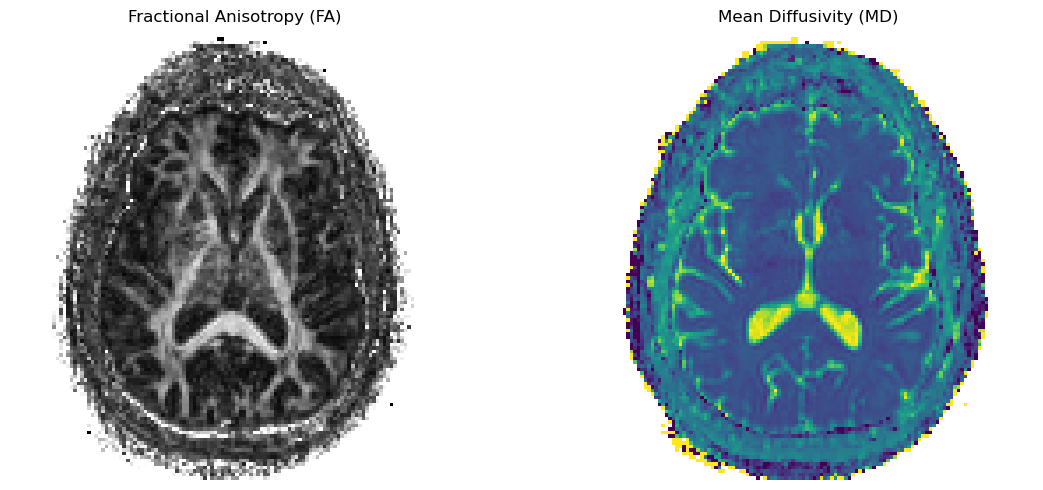

In [3]:
slice_num = fa.shape[2] // 2

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(
    fa[:, :, slice_num].T,
    cmap="gray",
    origin="lower",
    vmin=0,
    vmax=1
)
axes[0].set_title("Fractional Anisotropy (FA)")
axes[0].axis("off")

axes[1].imshow(
    md[:, :, slice_num].T,
    cmap="viridis",
    origin="lower",
    vmin=0,
    vmax=0.003
)
axes[1].set_title("Mean Diffusivity (MD)")
axes[1].axis("off")

plt.tight_layout()
plt.show()

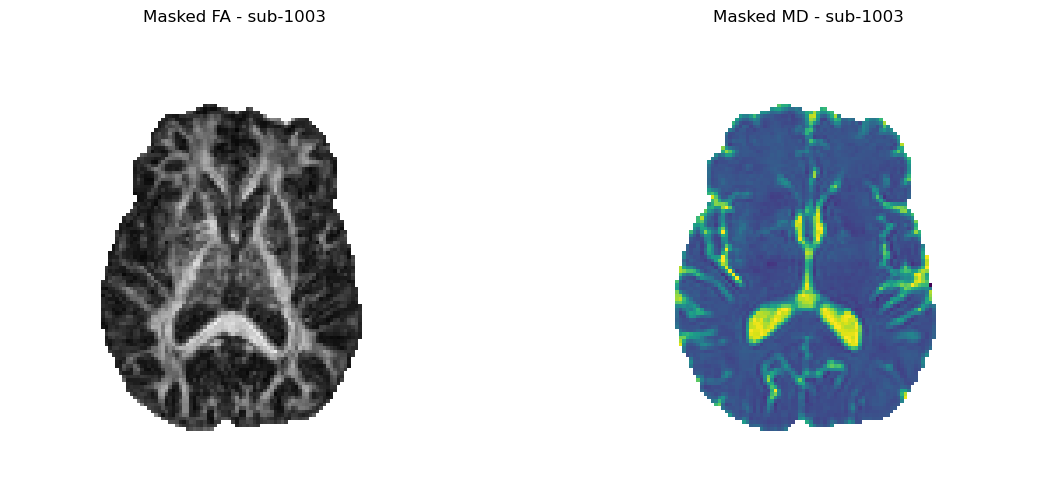

In [4]:
fa_masked = np.where(mask > 0, fa, np.nan)
md_masked = np.where(mask > 0, md, np.nan)

slice_num = fa.shape[2] // 2

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(
    fa_masked[:, :, slice_num].T,
    cmap="gray",
    origin="lower",
    vmin=0,
    vmax=1
)
axes[0].set_title("Masked FA - sub-1003")
axes[0].axis("off")

axes[1].imshow(
    md_masked[:, :, slice_num].T,
    cmap="viridis",
    origin="lower",
    vmin=0,
    vmax=0.003
)
axes[1].set_title("Masked MD - sub-1003")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [5]:
# Select valid brain voxels
valid_fa = (mask > 0) & np.isfinite(fa) & (fa >= 0) & (fa <= 1)
valid_md = (mask > 0) & np.isfinite(md) & (md >= 0)

# Calculate mean values
mean_fa = np.mean(fa[valid_fa])
mean_md = np.mean(md[valid_md])

print("Participant: sub-1003")
print(f"Mean FA: {mean_fa:.4f}")
print(f"Mean MD: {mean_md:.6f} mm²/s")
print(f"FA voxels included: {valid_fa.sum()}")
print(f"MD voxels included: {valid_md.sum()}")

Participant: sub-1003
Mean FA: 0.2717
Mean MD: 0.001013 mm²/s
FA voxels included: 162736
MD voxels included: 162785


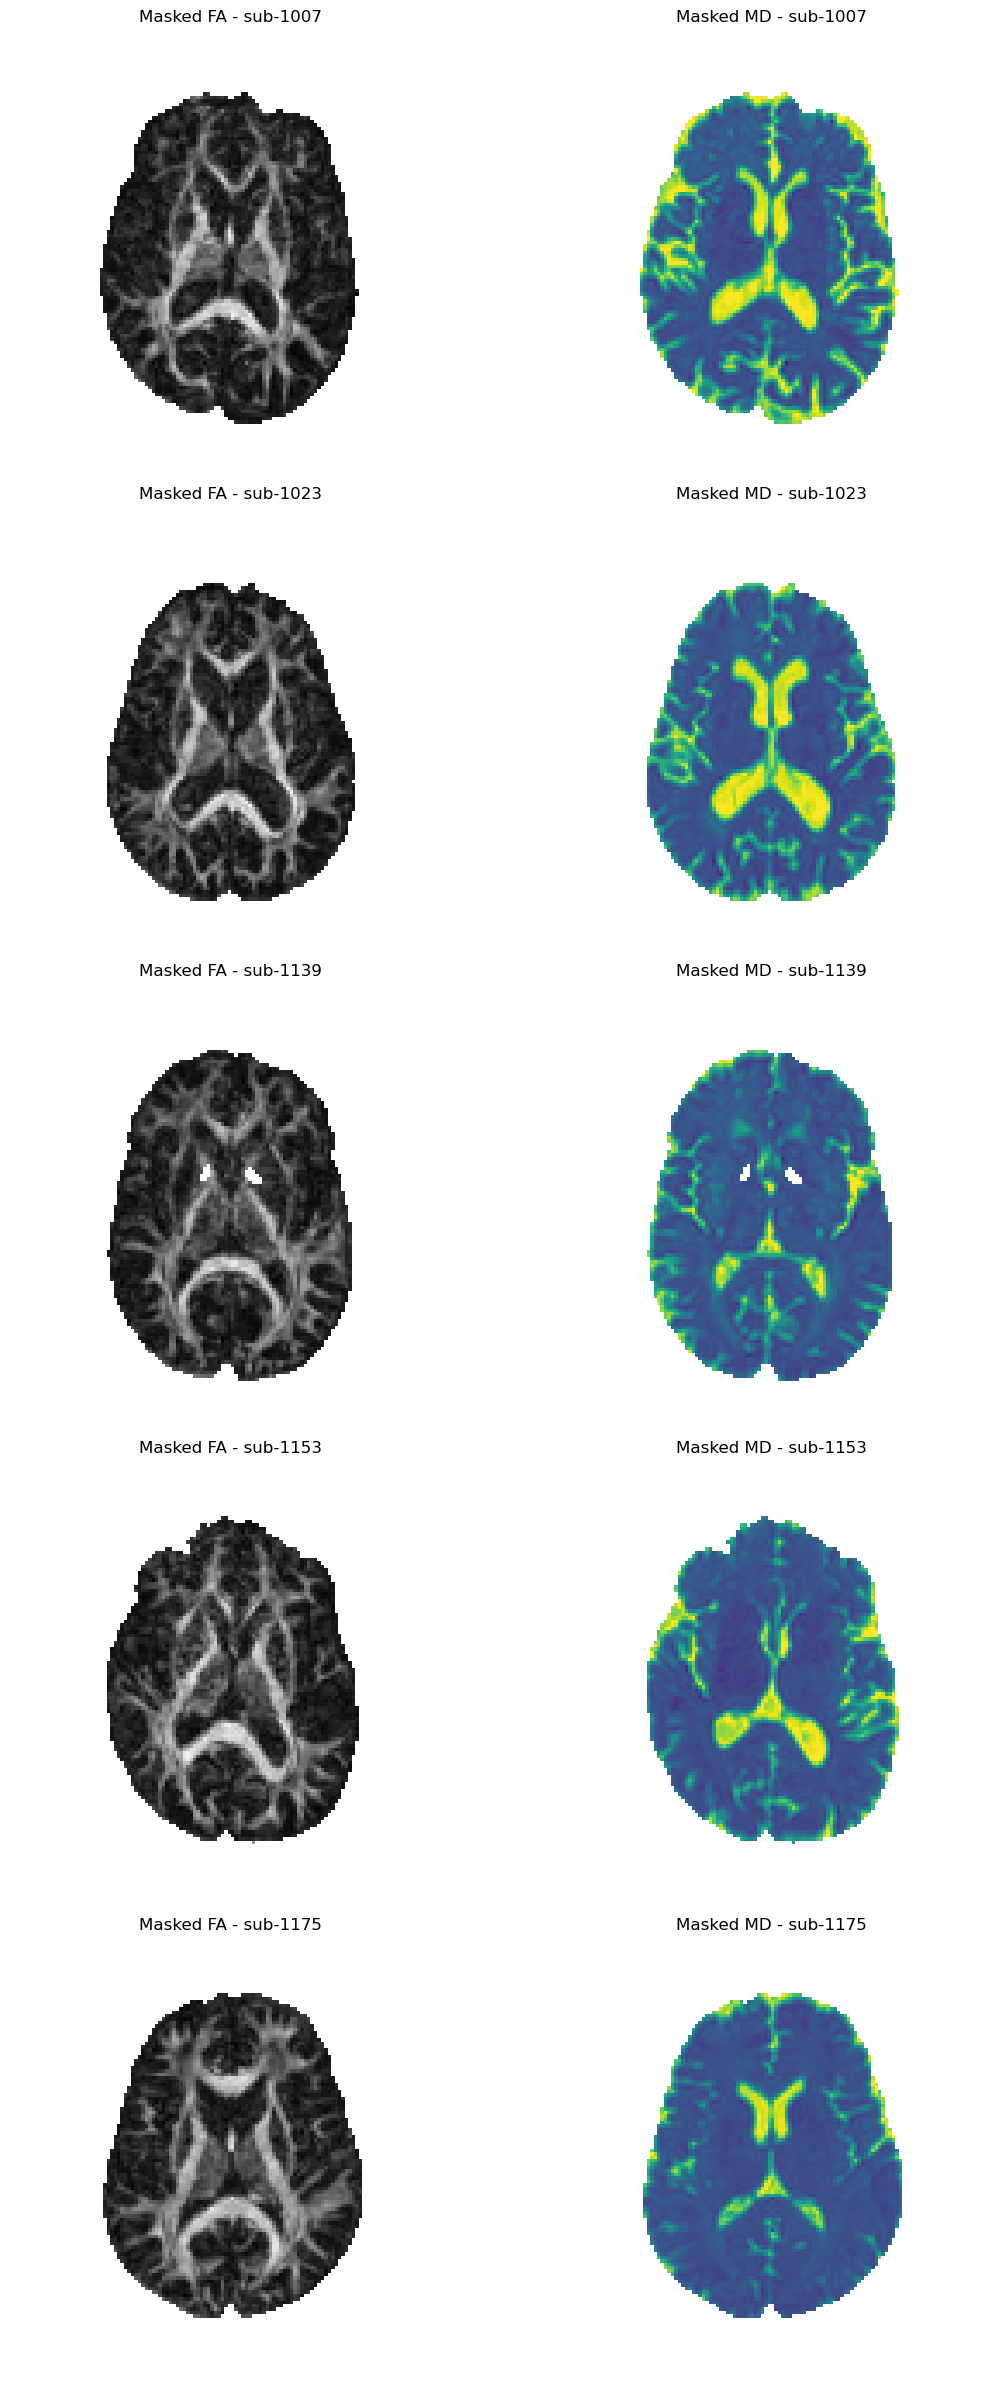

Images saved to: /nas/longleaf/home/emtubbs/NSCI270/dti_preprocessed/FA_MD_all_subjects.png


In [1]:

import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
from pathlib import Path

# Participants to visualize
subjects = ["1007", "1023", "1139", "1153", "1175"]

# Location of processed DTI files
base = Path.home() / "NSCI270" / "dti_preprocessed"

fig, axes = plt.subplots(5, 2, figsize=(12, 24))

for i, sub in enumerate(subjects):
    folder = base / f"sub-{sub}"

    # Load FA, MD, and brain mask
    fa = nib.load(str(folder / "FA.nii.gz")).get_fdata()
    md = nib.load(str(folder / "MD.nii.gz")).get_fdata()
    mask = nib.load(str(folder / "brain_mask.nii.gz")).get_fdata() > 0

    # Apply mask and hide background
    fa_masked = np.ma.masked_where(~mask, fa)
    md_masked = np.ma.masked_where(~mask, md)

    # Choose middle axial slice
    z = fa.shape[2] // 2

    # FA image
    axes[i, 0].imshow(
        np.rot90(fa_masked[:, :, z]),
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[i, 0].set_title(f"Masked FA - sub-{sub}")
    axes[i, 0].axis("off")

    # MD image
    axes[i, 1].imshow(
        np.rot90(md_masked[:, :, z]),
        cmap="viridis",
        vmin=0,
        vmax=0.003
    )
    axes[i, 1].set_title(f"Masked MD - sub-{sub}")
    axes[i, 1].axis("off")

plt.tight_layout()

# Save figure
output = base / "FA_MD_all_subjects.png"
plt.savefig(output, dpi=300, bbox_inches="tight")

plt.show()

print("Images saved to:", output)


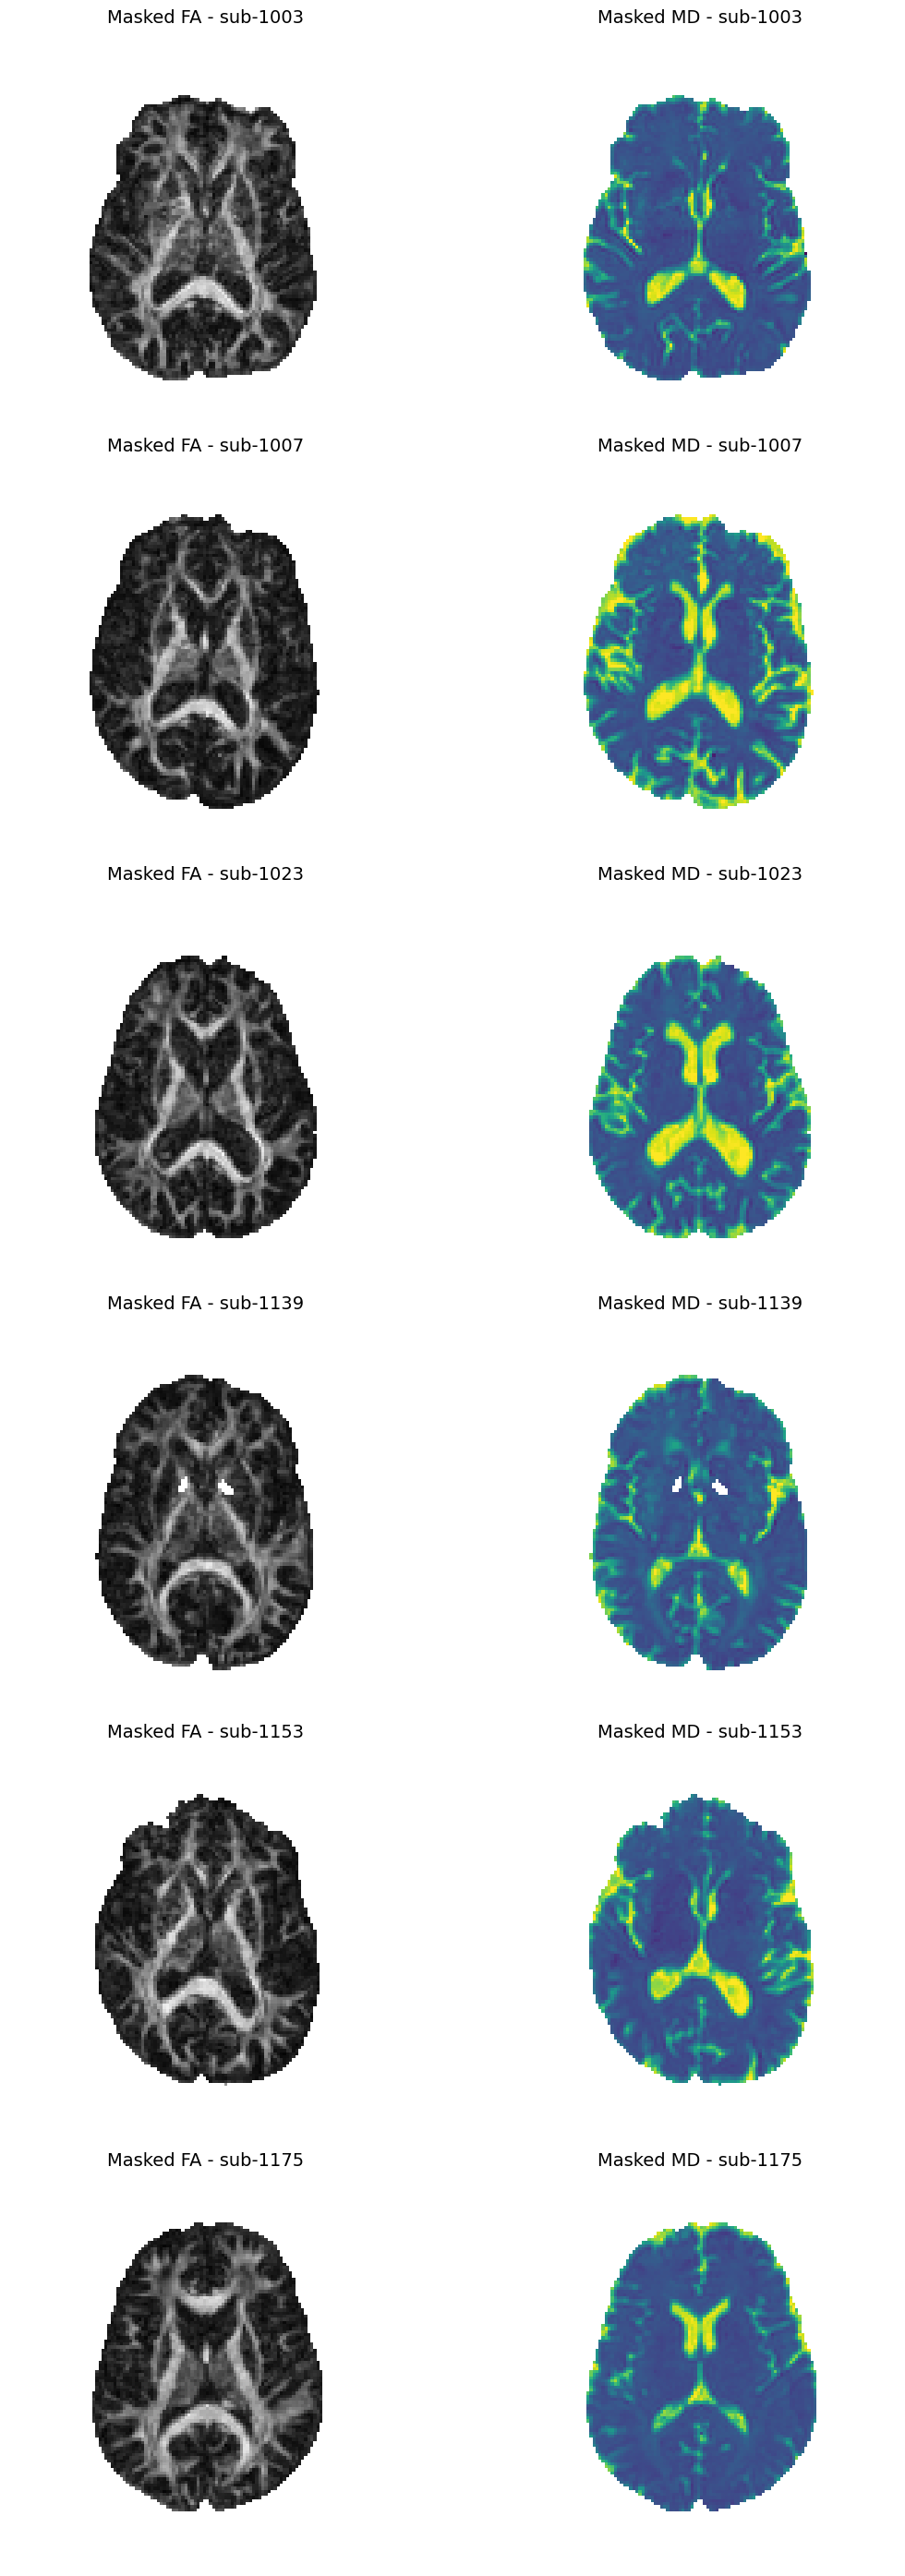

Figure saved to: /nas/longleaf/home/emtubbs/NSCI270/dti_preprocessed/FA_MD_all_6_subjects.png


In [2]:

import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
from pathlib import Path

# All six participants
subjects = ["1003", "1007", "1023", "1139", "1153", "1175"]

# Location of processed DTI files
base = Path.home() / "NSCI270" / "dti_preprocessed"

# Create figure with 6 rows and 2 columns
fig, axes = plt.subplots(6, 2, figsize=(12, 28))

for i, sub in enumerate(subjects):
    folder = base / f"sub-{sub}"

    # Load FA, MD, and brain mask
    fa = nib.load(str(folder / "FA.nii.gz")).get_fdata()
    md = nib.load(str(folder / "MD.nii.gz")).get_fdata()
    mask = nib.load(str(folder / "brain_mask.nii.gz")).get_fdata() > 0

    # Apply brain mask
    fa_masked = np.ma.masked_where(~mask, fa)
    md_masked = np.ma.masked_where(~mask, md)

    # Select middle axial slice
    z = fa.shape[2] // 2

    # Display FA
    axes[i, 0].imshow(
        np.rot90(fa_masked[:, :, z]),
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[i, 0].set_title(f"Masked FA - sub-{sub}", fontsize=14)
    axes[i, 0].axis("off")

    # Display MD
    axes[i, 1].imshow(
        np.rot90(md_masked[:, :, z]),
        cmap="viridis",
        vmin=0,
        vmax=0.003
    )
    axes[i, 1].set_title(f"Masked MD - sub-{sub}", fontsize=14)
    axes[i, 1].axis("off")

plt.tight_layout()

# Save figure as PNG
output = base / "FA_MD_all_6_subjects.png"
plt.savefig(output, dpi=300, bbox_inches="tight")

plt.show()

print("Figure saved to:", output)


In [3]:
import nibabel as nib
from pathlib import Path

base = Path.home() / "NSCI270/dti_preprocessed"

for sub in ["1003", "1007", "1023", "1139", "1153", "1175"]:
    path = base / f"sub-{sub}" / "FA.nii.gz"

    img = nib.load(str(path))

    print(f"sub-{sub}")
    print("Image dimensions:", img.shape)
    print("Voxel size:", img.header.get_zooms()[:3])
    print()

sub-1003
Image dimensions: (128, 128, 50)
Voxel size: (1.75, 1.75, 3.00017)

sub-1007
Image dimensions: (128, 128, 50)
Voxel size: (1.75, 1.75, 3.0)

sub-1023
Image dimensions: (128, 128, 50)
Voxel size: (1.75, 1.75, 3.0)

sub-1139
Image dimensions: (128, 128, 50)
Voxel size: (1.75, 1.75, 3.0)

sub-1153
Image dimensions: (128, 128, 50)
Voxel size: (1.75, 1.75, 3.0)

sub-1175
Image dimensions: (128, 128, 50)
Voxel size: (1.75, 1.75, 3.0)



In [4]:
import nibabel as nib
from pathlib import Path
import numpy as np

base = Path.home() / "NSCI270/dti_preprocessed"

subjects = ["1003", "1007", "1023", "1139", "1153", "1175"]

for sub in subjects:
    path = base / f"sub-{sub}" / "FA.nii.gz"
    img = nib.load(str(path))

    print(f"\nParticipant: sub-{sub}")
    print("Orientation:", nib.aff2axcodes(img.affine))
    print("Affine matrix:")
    print(np.round(img.affine, 3))
    print("-----------------------------")


Participant: sub-1003
Orientation: ('L', 'A', 'S')
Affine matrix:
[[-1.73700e+00 -2.08000e-01 -1.06000e-01  1.20575e+02]
 [-2.03000e-01  1.73400e+00 -2.02000e-01 -8.35920e+01]
 [-7.50000e-02  1.10000e-01  2.99100e+00 -6.76110e+01]
 [ 0.00000e+00  0.00000e+00  0.00000e+00  1.00000e+00]]
-----------------------------

Participant: sub-1007
Orientation: ('L', 'A', 'S')
Affine matrix:
[[-1.74900e+00 -6.00000e-02  7.00000e-03  1.14678e+02]
 [-6.00000e-02  1.74500e+00 -2.03000e-01 -9.80350e+01]
 [-0.00000e+00  1.18000e-01  2.99300e+00 -7.40260e+01]
 [ 0.00000e+00  0.00000e+00  0.00000e+00  1.00000e+00]]
-----------------------------

Participant: sub-1023
Orientation: ('L', 'A', 'S')
Affine matrix:
[[-1.74700e+00 -1.08000e-01  0.00000e+00  1.17635e+02]
 [-1.08000e-01  1.74700e+00 -0.00000e+00 -9.91120e+01]
 [ 0.00000e+00  0.00000e+00  3.00000e+00 -6.16910e+01]
 [ 0.00000e+00  0.00000e+00  0.00000e+00  1.00000e+00]]
-----------------------------

Participant: sub-1139
Orientation: ('L', 'A',

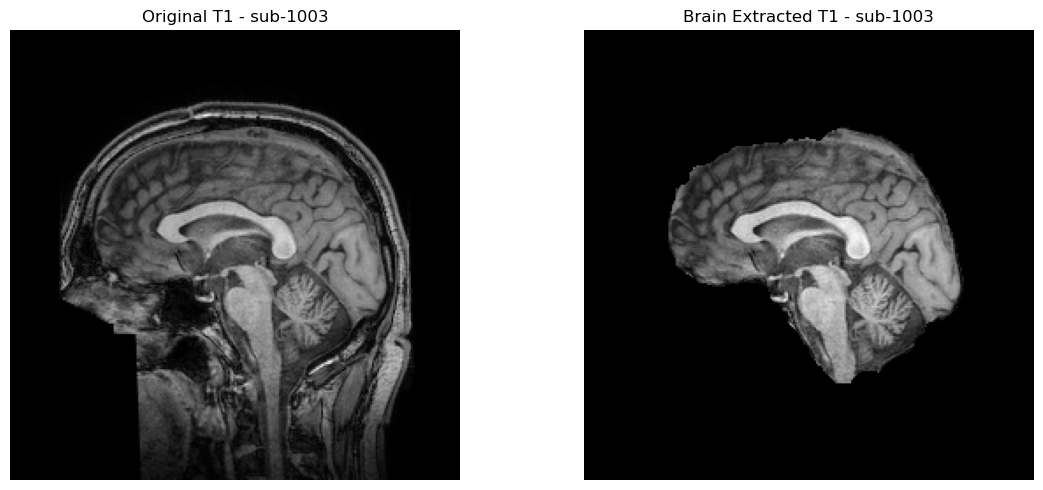

In [5]:
import nibabel as nib
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

base = Path.home() / "NSCI270"

original = nib.load(
    str(base / "ds004856_multimodal/sub-1003/ses-wave3/anat/"
        "sub-1003_ses-wave3_acq-MPRAGE_run-1_T1w.nii.gz")
)

extracted = nib.load(
    str(base / "tract_analysis/sub-1003/T1_brain.nii.gz")
)

original_data = original.get_fdata()
brain_data = extracted.get_fdata()

slice_num = original_data.shape[2] // 2

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(
    original_data[:, :, slice_num].T,
    cmap="gray",
    origin="lower"
)
axes[0].set_title("Original T1 - sub-1003")

axes[1].imshow(
    brain_data[:, :, slice_num].T,
    cmap="gray",
    origin="lower"
)
axes[1].set_title("Brain Extracted T1 - sub-1003")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

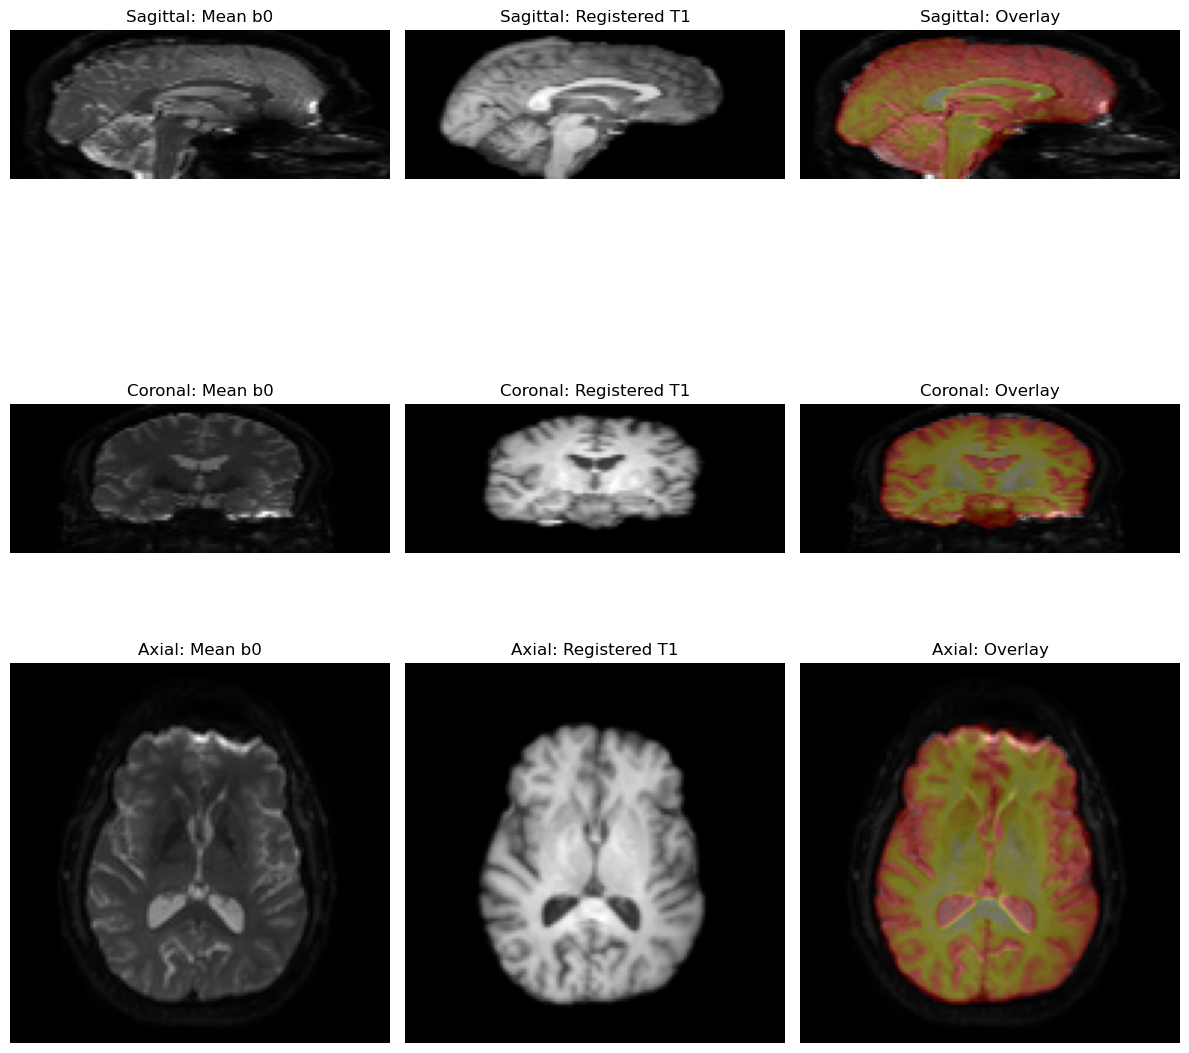

In [6]:
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

base = Path.home() / "NSCI270"

b0_img = nib.load(str(
    base / "dti_preprocessed/sub-1003/b0_mean_correct.nii.gz"
))

t1_img = nib.load(str(
    base / "tract_analysis/sub-1003/T1_in_DTI.nii.gz"
))

b0 = b0_img.get_fdata()
t1 = t1_img.get_fdata()

# Choose middle slices in three anatomical planes
slices = [s // 2 for s in b0.shape]

fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for row, (axis, slice_num, name) in enumerate(
    zip(range(3), slices, ["Sagittal", "Coronal", "Axial"])
):
    if axis == 0:
        b0_slice = b0[slice_num, :, :]
        t1_slice = t1[slice_num, :, :]
    elif axis == 1:
        b0_slice = b0[:, slice_num, :]
        t1_slice = t1[:, slice_num, :]
    else:
        b0_slice = b0[:, :, slice_num]
        t1_slice = t1[:, :, slice_num]

    b0_slice = b0_slice.T
    t1_slice = t1_slice.T

    axes[row, 0].imshow(b0_slice, cmap="gray", origin="lower")
    axes[row, 0].set_title(f"{name}: Mean b0")

    axes[row, 1].imshow(t1_slice, cmap="gray", origin="lower")
    axes[row, 1].set_title(f"{name}: Registered T1")

    axes[row, 2].imshow(b0_slice, cmap="gray", origin="lower")
    axes[row, 2].imshow(
        np.ma.masked_where(t1_slice <= 0, t1_slice),
        cmap="hot",
        alpha=0.35,
        origin="lower"
    )
    axes[row, 2].set_title(f"{name}: Overlay")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

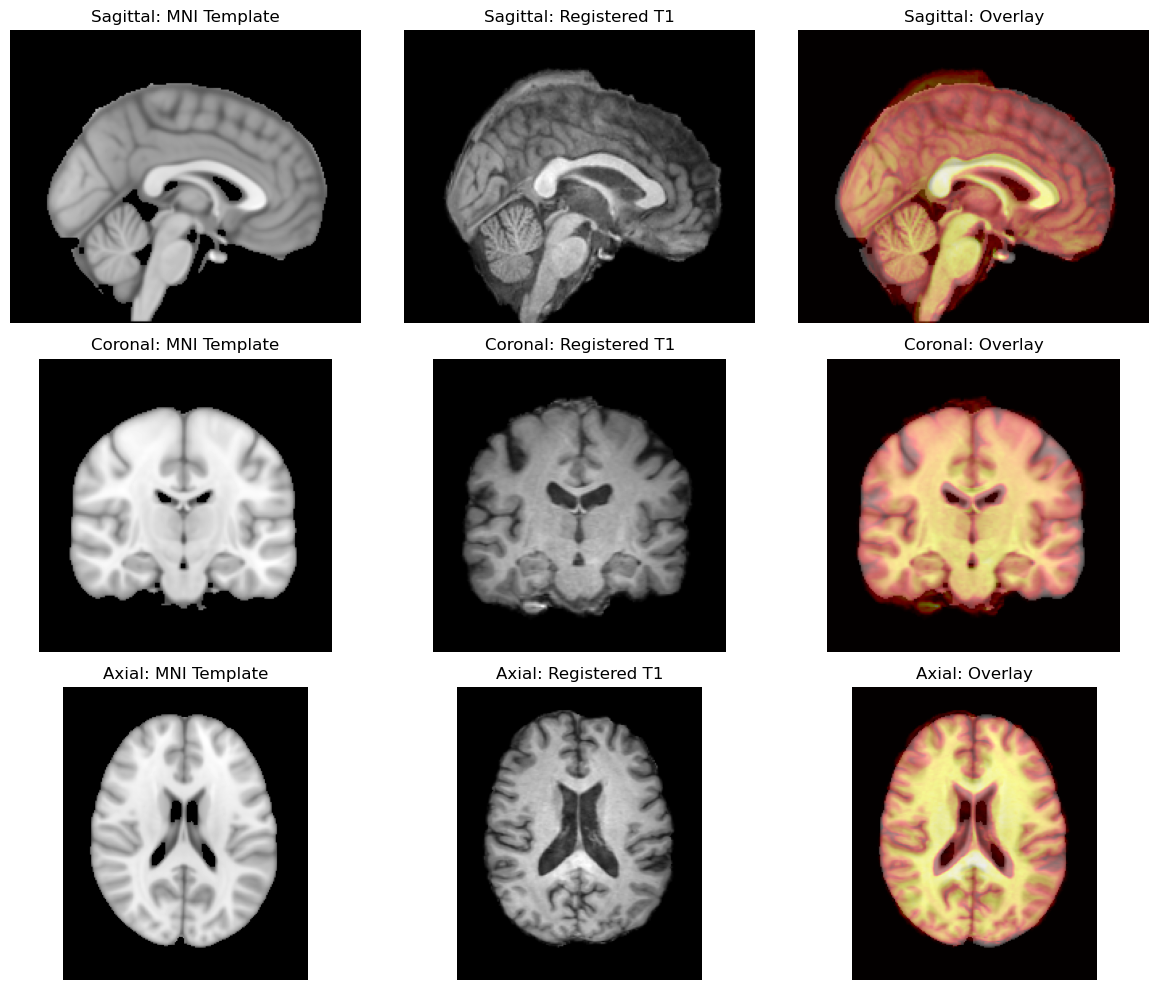

In [7]:
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt
import os

base = os.path.expanduser("~/NSCI270")

registered_path = f"{base}/tract_analysis/sub-1003/T1_in_MNI.nii.gz"

mni_path = (
    "/nas/longleaf/rhel9/apps/fsl/6.0.7.19/fsl/"
    "data/standard/MNI152_T1_1mm_brain.nii.gz"
)

registered = nib.load(registered_path)
mni = nib.load(mni_path)

reg_data = registered.get_fdata()
mni_data = mni.get_fdata()

# Select central slices
x, y, z = np.array(mni_data.shape) // 2

fig, axes = plt.subplots(3, 3, figsize=(12, 10))

views = [
    ("Sagittal", x, 0),
    ("Coronal", y, 1),
    ("Axial", z, 2)
]

for row, (name, index, axis) in enumerate(views):

    if axis == 0:
        template_slice = mni_data[index, :, :]
        registered_slice = reg_data[index, :, :]
    elif axis == 1:
        template_slice = mni_data[:, index, :]
        registered_slice = reg_data[:, index, :]
    else:
        template_slice = mni_data[:, :, index]
        registered_slice = reg_data[:, :, index]

    template_slice = np.rot90(template_slice)
    registered_slice = np.rot90(registered_slice)

    axes[row, 0].imshow(template_slice, cmap="gray")
    axes[row, 0].set_title(f"{name}: MNI Template")

    axes[row, 1].imshow(registered_slice, cmap="gray")
    axes[row, 1].set_title(f"{name}: Registered T1")

    axes[row, 2].imshow(template_slice, cmap="gray")
    axes[row, 2].imshow(
        registered_slice,
        cmap="hot",
        alpha=0.4
    )
    axes[row, 2].set_title(f"{name}: Overlay")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

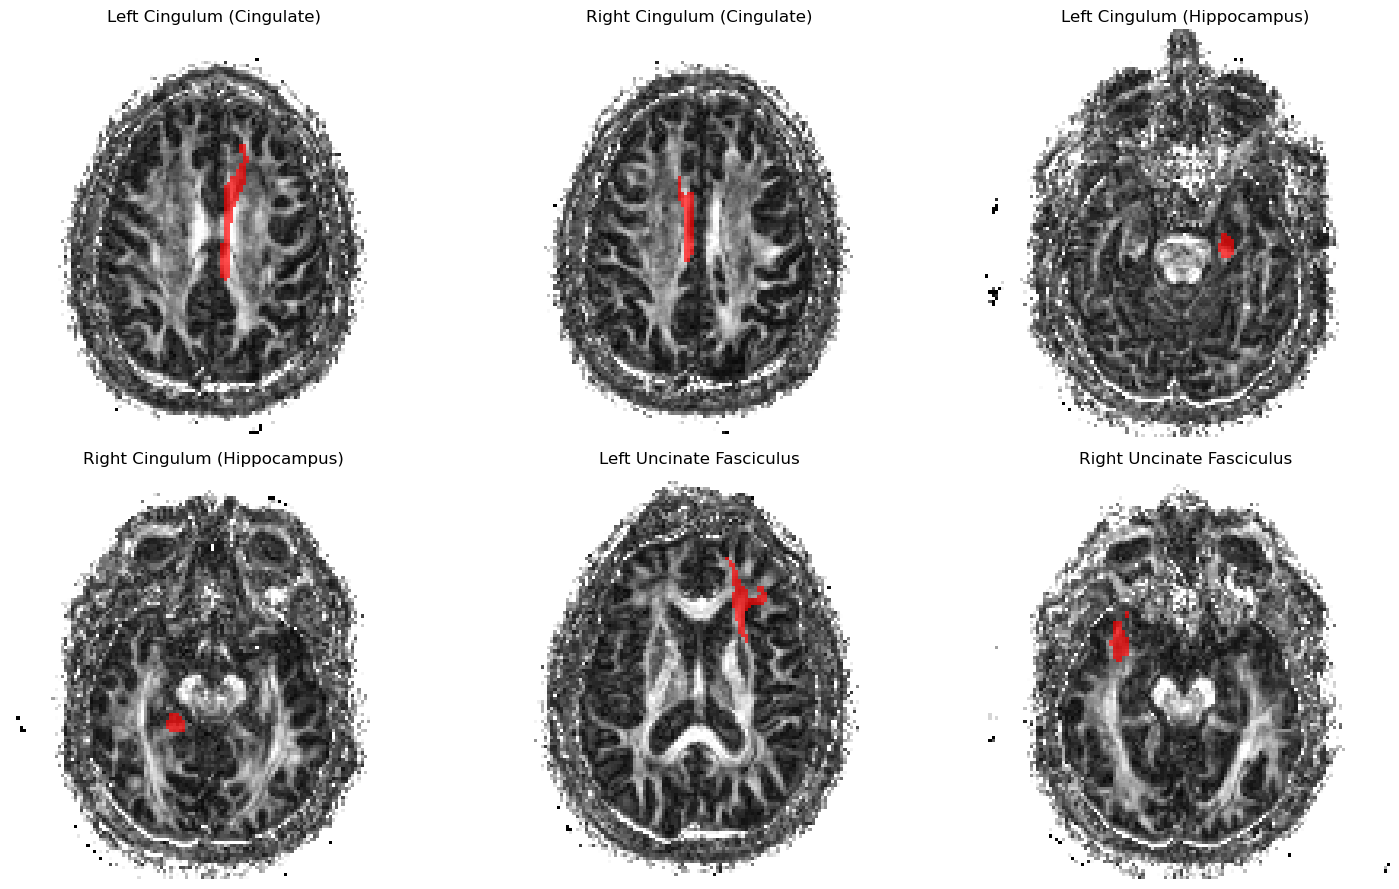

In [8]:
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt
import os

base = os.path.expanduser("~/NSCI270")

subject = "1003"

fa_path = f"{base}/dti_preprocessed/sub-{subject}/FA.nii.gz"

fa_img = nib.load(fa_path)
fa = fa_img.get_fdata()

tracts = {
    4: "Left Cingulum (Cingulate)",
    5: "Right Cingulum (Cingulate)",
    6: "Left Cingulum (Hippocampus)",
    7: "Right Cingulum (Hippocampus)",
    16: "Left Uncinate Fasciculus",
    17: "Right Uncinate Fasciculus"
}

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, (i, name) in zip(axes.flat, tracts.items()):

    mask_path = (
        f"{base}/tract_analysis/sub-{subject}/"
        f"tract_masks/tract_{i}_DTI_prob.nii.gz"
    )

    mask_img = nib.load(mask_path)
    mask = mask_img.get_fdata()

    # Select the axial slice containing the most tract voxels
    binary = mask > 10
    z = np.argmax(binary.sum(axis=(0, 1)))

    fa_slice = np.rot90(fa[:, :, z])
    mask_slice = np.rot90(binary[:, :, z])

    ax.imshow(fa_slice, cmap="gray", vmin=0, vmax=0.8)

    overlay = np.ma.masked_where(~mask_slice, mask_slice)

    ax.imshow(overlay, cmap="autumn", alpha=0.7,
              interpolation="nearest")

    ax.set_title(name)
    ax.axis("off")

plt.tight_layout()
plt.show()

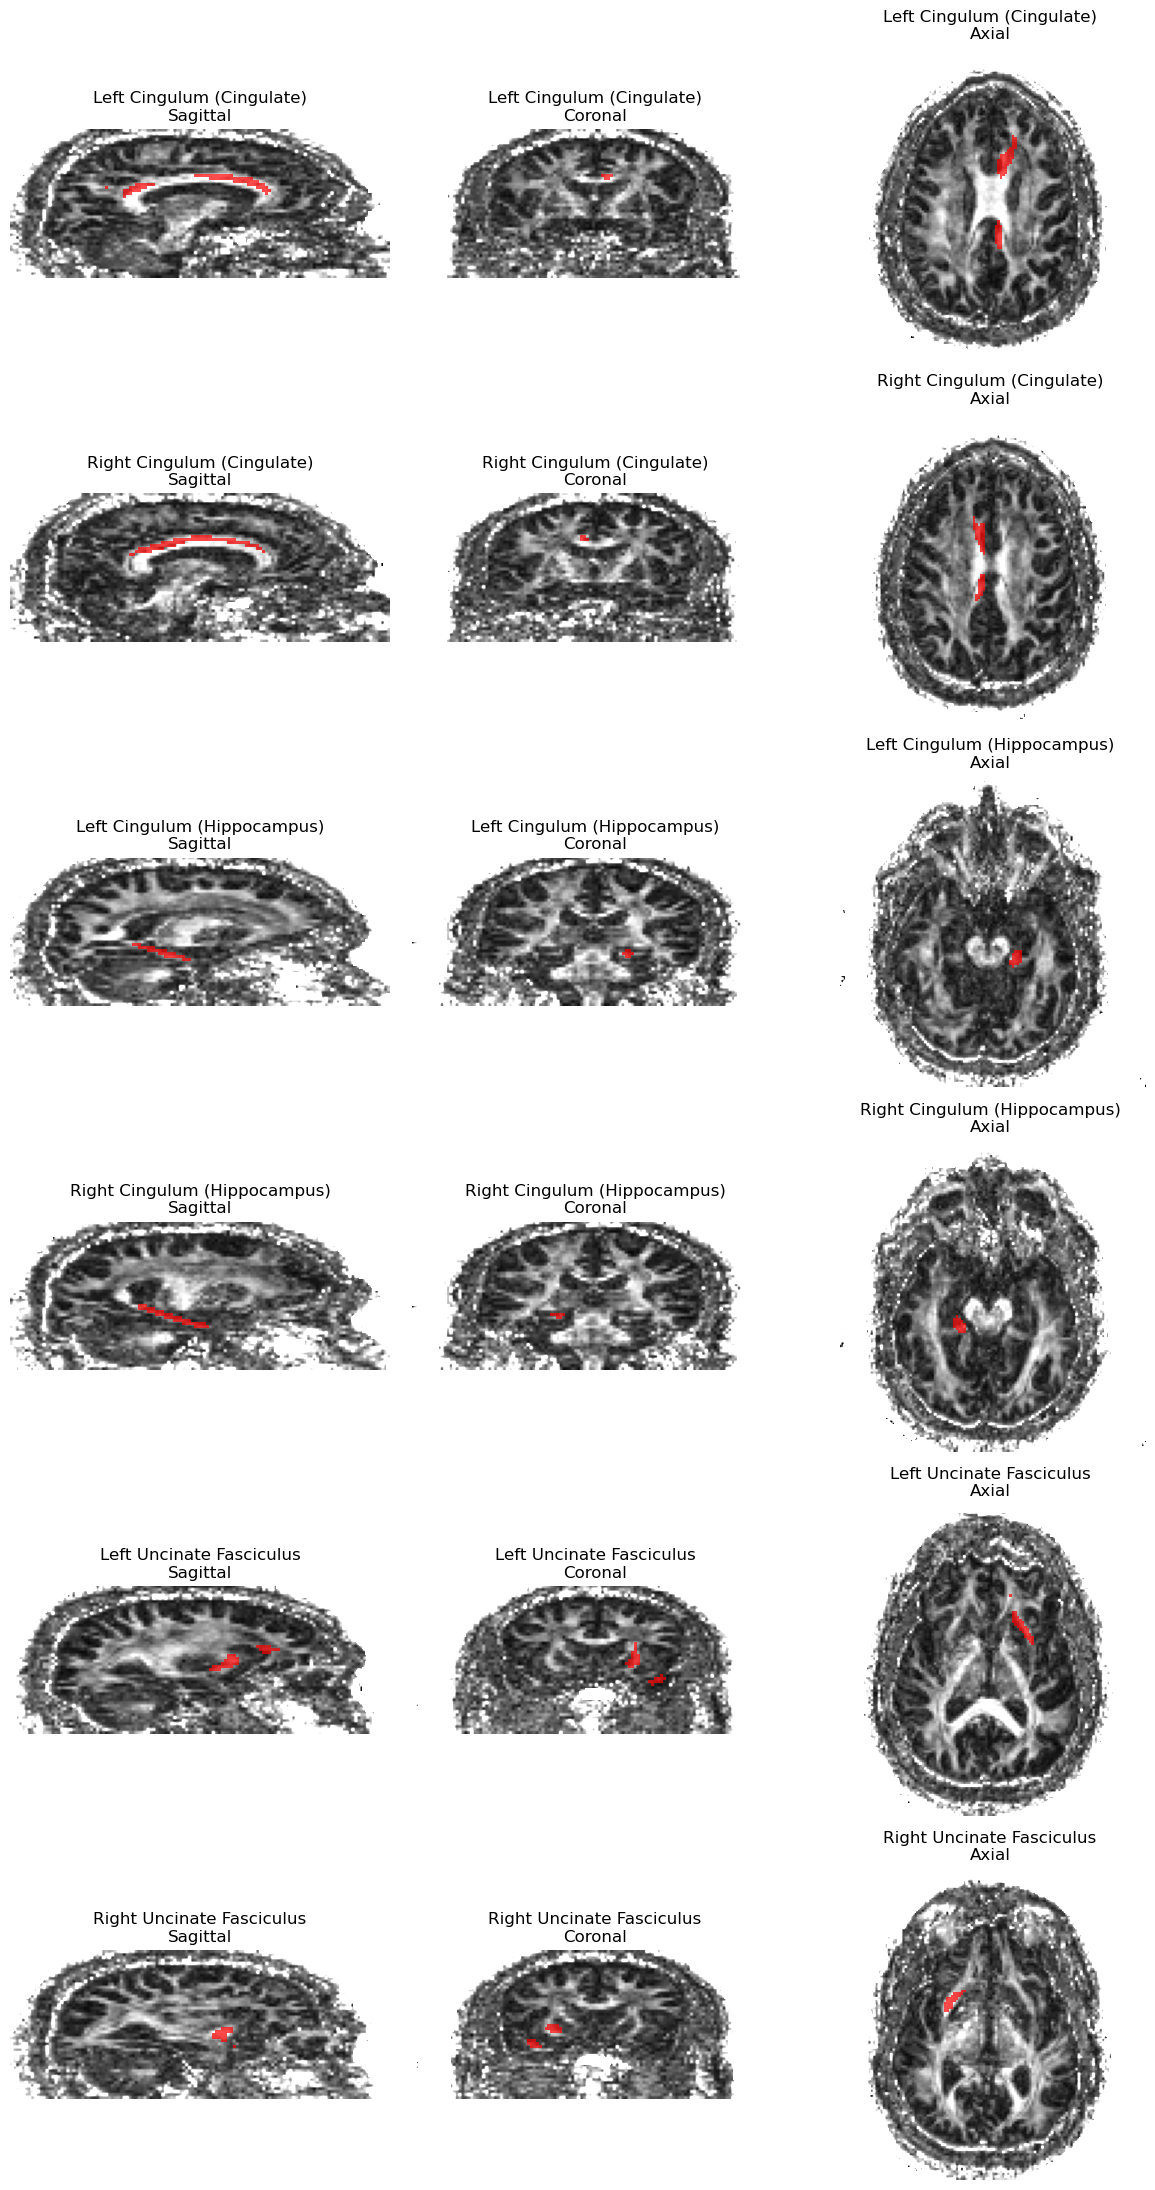

In [9]:
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt
import os

base = os.path.expanduser("~/NSCI270")
subject = "1003"

fa_img = nib.load(
    f"{base}/dti_preprocessed/sub-{subject}/FA.nii.gz"
)
fa = fa_img.get_fdata()

tracts = {
    4: "Left Cingulum (Cingulate)",
    5: "Right Cingulum (Cingulate)",
    6: "Left Cingulum (Hippocampus)",
    7: "Right Cingulum (Hippocampus)",
    16: "Left Uncinate Fasciculus",
    17: "Right Uncinate Fasciculus"
}

fig, axes = plt.subplots(6, 3, figsize=(12, 22))

for row, (i, name) in enumerate(tracts.items()):

    path = (
        f"{base}/tract_analysis/sub-{subject}/"
        f"tract_masks/tract_{i}_DTI_prob.nii.gz"
    )

    mask_img = nib.load(path)
    mask = mask_img.get_fdata() > 10

    coords = np.array(np.where(mask))

    if coords.size == 0:
        print(f"No voxels found for tract {i}")
        continue

    # Select slices through the center of the tract
    x, y, z = np.median(coords, axis=1).astype(int)

    views = [
        (fa[x, :, :], mask[x, :, :], "Sagittal"),
        (fa[:, y, :], mask[:, y, :], "Coronal"),
        (fa[:, :, z], mask[:, :, z], "Axial")
    ]

    for col, (brain, tract, view) in enumerate(views):

        ax = axes[row, col]

        ax.imshow(
            np.rot90(brain),
            cmap="gray",
            vmin=0,
            vmax=0.8
        )

        overlay = np.ma.masked_where(
            ~np.rot90(tract),
            np.rot90(tract)
        )

        ax.imshow(
            overlay,
            cmap="autumn",
            alpha=0.7,
            interpolation="nearest"
        )

        ax.set_title(f"{name}\n{view}")
        ax.axis("off")

plt.tight_layout()
plt.show()

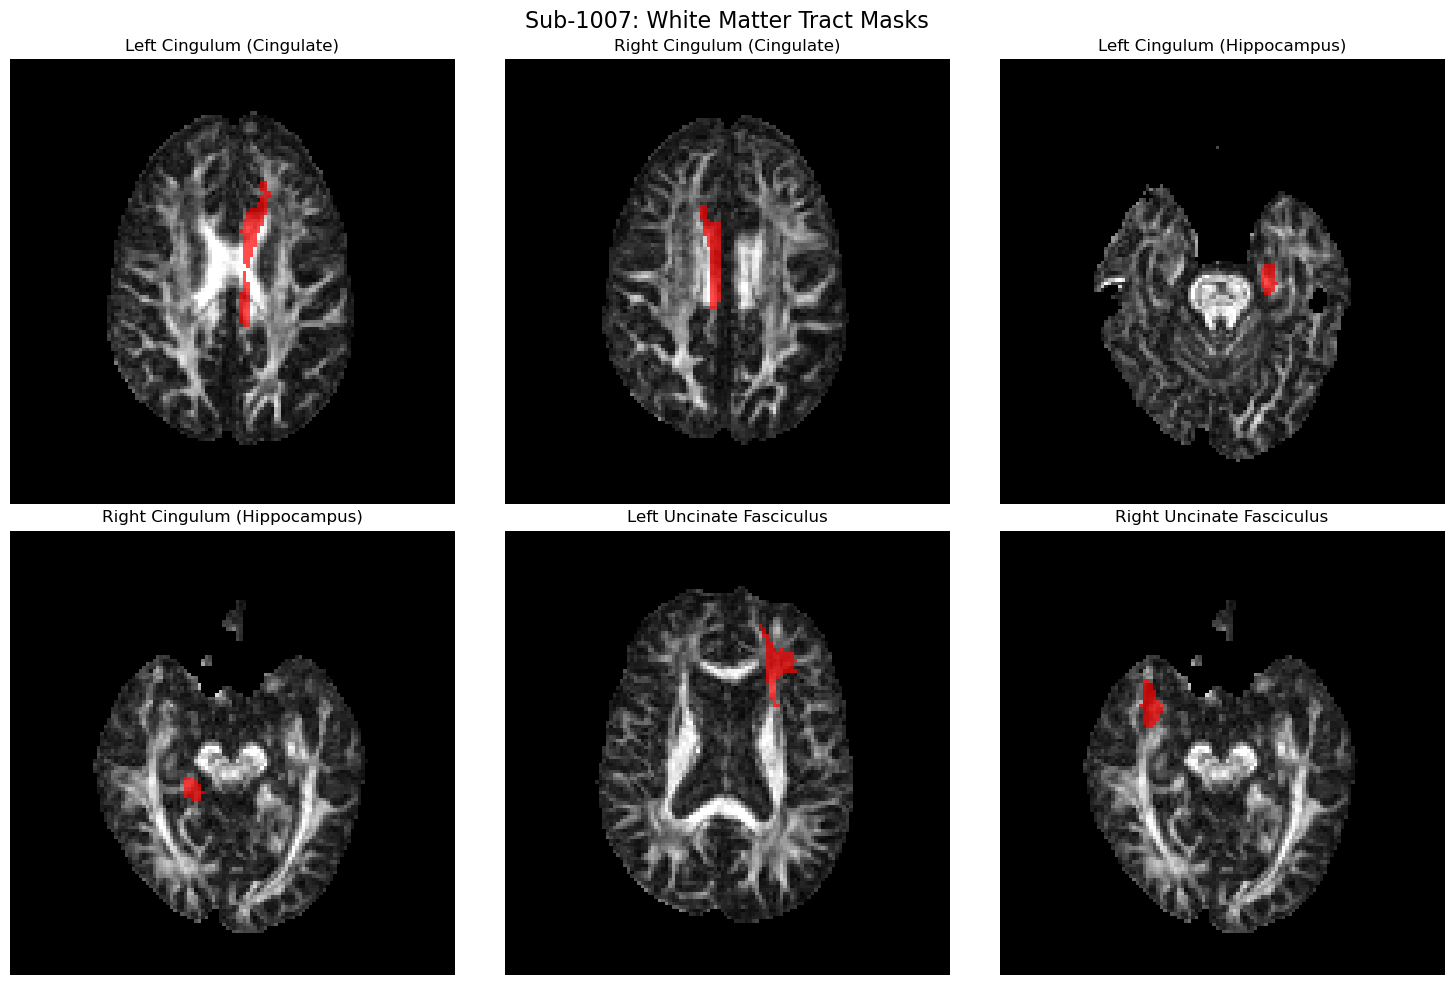

In [11]:
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

base = Path.home() / "NSCI270"

fa_img = nib.load(
    base / "tract_analysis/sub-1007/FA_brain.nii.gz"
)
fa = fa_img.get_fdata()

tracts = {
    4: "Left Cingulum (Cingulate)",
    5: "Right Cingulum (Cingulate)",
    6: "Left Cingulum (Hippocampus)",
    7: "Right Cingulum (Hippocampus)",
    16: "Left Uncinate Fasciculus",
    17: "Right Uncinate Fasciculus"
}

fig, axes = plt.subplots(2, 3, figsize=(15, 10))

for ax, (i, name) in zip(axes.flat, tracts.items()):

    mask_img = nib.load(
        base / f"tract_analysis/sub-1007/tract_masks/tract_{i}_DTI_prob.nii.gz"
    )

    mask = mask_img.get_fdata() > 10

    if not np.any(mask):
        ax.set_title(f"{name}: Empty mask")
        ax.axis("off")
        continue

    # Choose an axial slice containing the most tract voxels
    z = np.argmax(mask.sum(axis=(0, 1)))

    ax.imshow(
        fa[:, :, z].T,
        cmap="gray",
        origin="lower",
        vmin=0,
        vmax=0.8
    )

    ax.imshow(
        np.ma.masked_where(~mask[:, :, z].T, mask[:, :, z].T),
        cmap="autumn",
        origin="lower",
        alpha=0.7
    )

    ax.set_title(name)
    ax.axis("off")

plt.suptitle("Sub-1007: White Matter Tract Masks", fontsize=16)
plt.tight_layout()
plt.show()

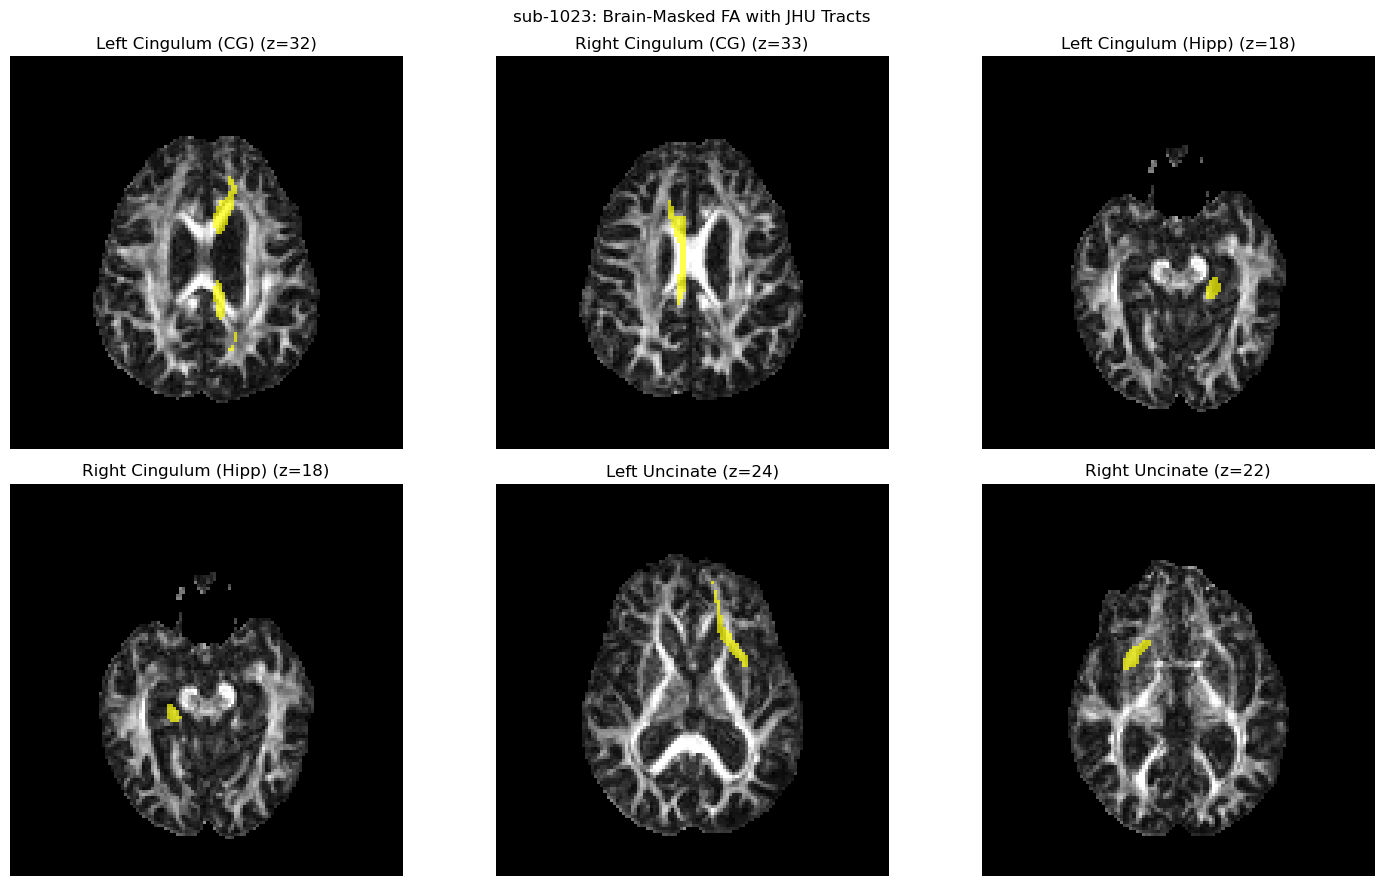

In [13]:

import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

base = Path.home() / "NSCI270"
subject = "sub-1023"

# Load FA and brain mask
fa_img = nib.load(str(base / "dti_preprocessed" / subject / "FA.nii.gz"))
fa = fa_img.get_fdata()

brain_img = nib.load(str(base / "dti_preprocessed" / subject / "brain_mask.nii.gz"))
brain_mask = brain_img.get_fdata() > 0

# Remove background outside the brain
fa_clean = np.where(brain_mask, fa, 0)

tracts = [4, 5, 6, 7, 16, 17]
names = [
    "Left Cingulum (CG)",
    "Right Cingulum (CG)",
    "Left Cingulum (Hipp)",
    "Right Cingulum (Hipp)",
    "Left Uncinate",
    "Right Uncinate"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, tract, name in zip(axes.flat, tracts, names):

    path = base / "tract_analysis" / subject / f"tract_{tract}_brain.nii.gz"
    mask_img = nib.load(str(path))
    mask = mask_img.get_fdata() > 0

    # Select a slice containing the tract
    coords = np.where(mask)
    slice_z = int(np.median(coords[2]))

    # Display cleaned FA
    ax.imshow(
        fa_clean[:, :, slice_z].T,
        cmap="gray",
        origin="lower",
        vmin=0,
        vmax=0.8
    )

    # Display tract overlay
    overlay = np.ma.masked_where(
        ~mask[:, :, slice_z],
        mask[:, :, slice_z]
    )

    ax.imshow(
        overlay.T,
        cmap="autumn",
        origin="lower",
        alpha=0.7,
        vmin=0,
        vmax=1
    )

    ax.set_title(f"{name} (z={slice_z})")
    ax.axis("off")

plt.suptitle("sub-1023: Brain-Masked FA with JHU Tracts")
plt.tight_layout()
plt.show()

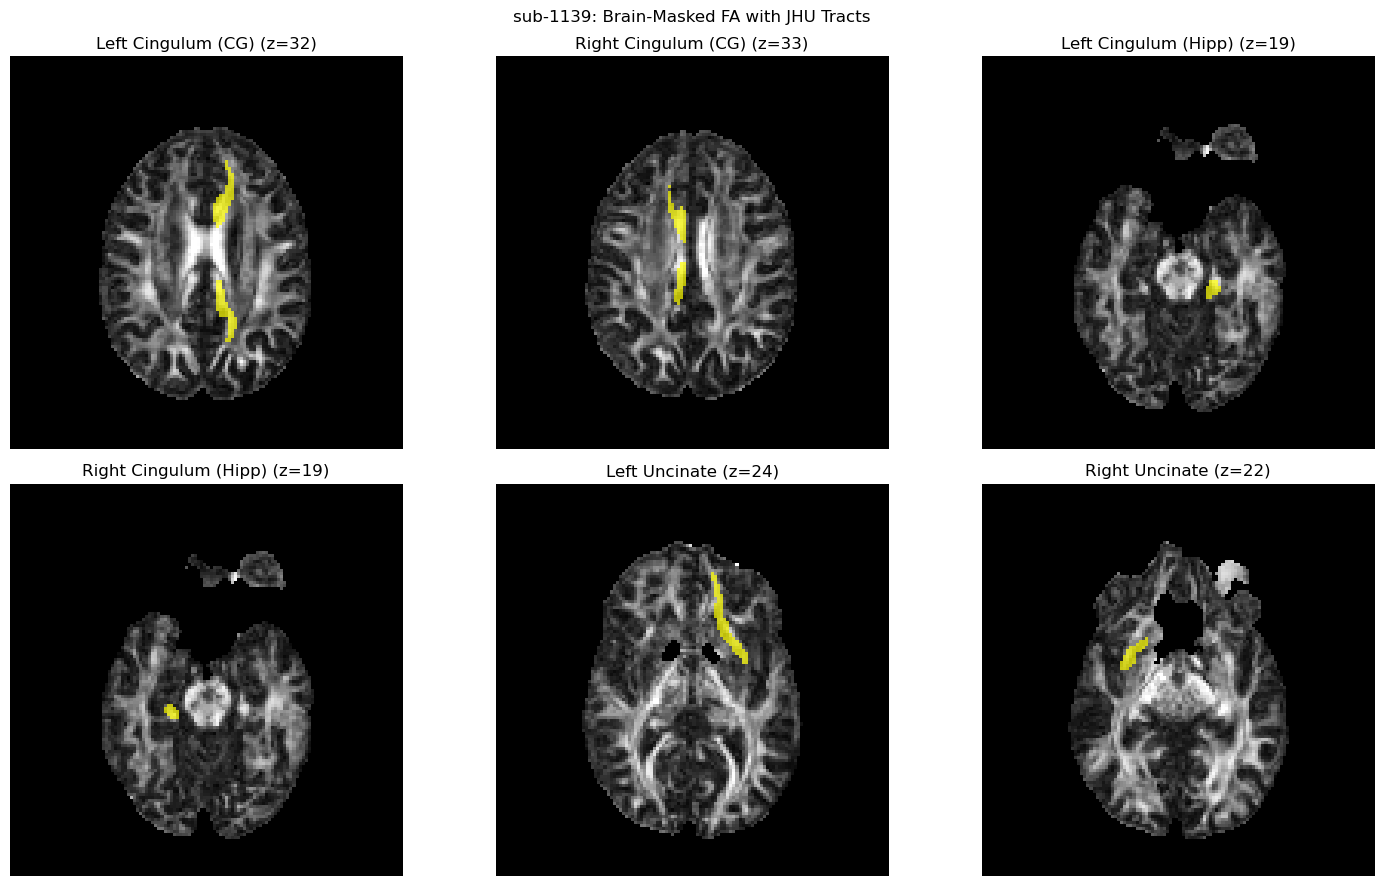

In [14]:

import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

base = Path.home() / "NSCI270"
subject = "sub-1139"

# Load FA image
fa_img = nib.load(str(base / "dti_preprocessed" / subject / "FA.nii.gz"))
fa = fa_img.get_fdata()

# Load brain mask
brain_img = nib.load(str(base / "dti_preprocessed" / subject / "brain_mask.nii.gz"))
brain_mask = brain_img.get_fdata() > 0

# Remove background noise
fa_clean = np.where(brain_mask, fa, 0)

# Six white matter tracts
tracts = [4, 5, 6, 7, 16, 17]

names = [
    "Left Cingulum (CG)",
    "Right Cingulum (CG)",
    "Left Cingulum (Hipp)",
    "Right Cingulum (Hipp)",
    "Left Uncinate",
    "Right Uncinate"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, tract, name in zip(axes.flat, tracts, names):

    path = base / "tract_analysis" / subject / f"tract_{tract}_brain.nii.gz"
    mask_img = nib.load(str(path))
    mask = mask_img.get_fdata() > 0

    if mask.shape != fa.shape or not np.allclose(
        mask_img.affine, fa_img.affine, atol=1e-3
    ):
        raise ValueError(f"Tract {tract} is not aligned to the FA image grid")

    # Select slice containing tract
    coords = np.where(mask)
    slice_z = int(np.median(coords[2]))

    # Display FA image
    ax.imshow(
        fa_clean[:, :, slice_z].T,
        cmap="gray",
        origin="lower",
        vmin=0,
        vmax=0.8
    )

    # Display tract overlay
    overlay = np.ma.masked_where(
        ~mask[:, :, slice_z],
        mask[:, :, slice_z]
    )

    ax.imshow(
        overlay.T,
        cmap="autumn",
        origin="lower",
        alpha=0.7,
        vmin=0,
        vmax=1
    )

    ax.set_title(f"{name} (z={slice_z})")
    ax.axis("off")

plt.suptitle("sub-1139: Brain-Masked FA with JHU Tracts")
plt.tight_layout()
plt.show()


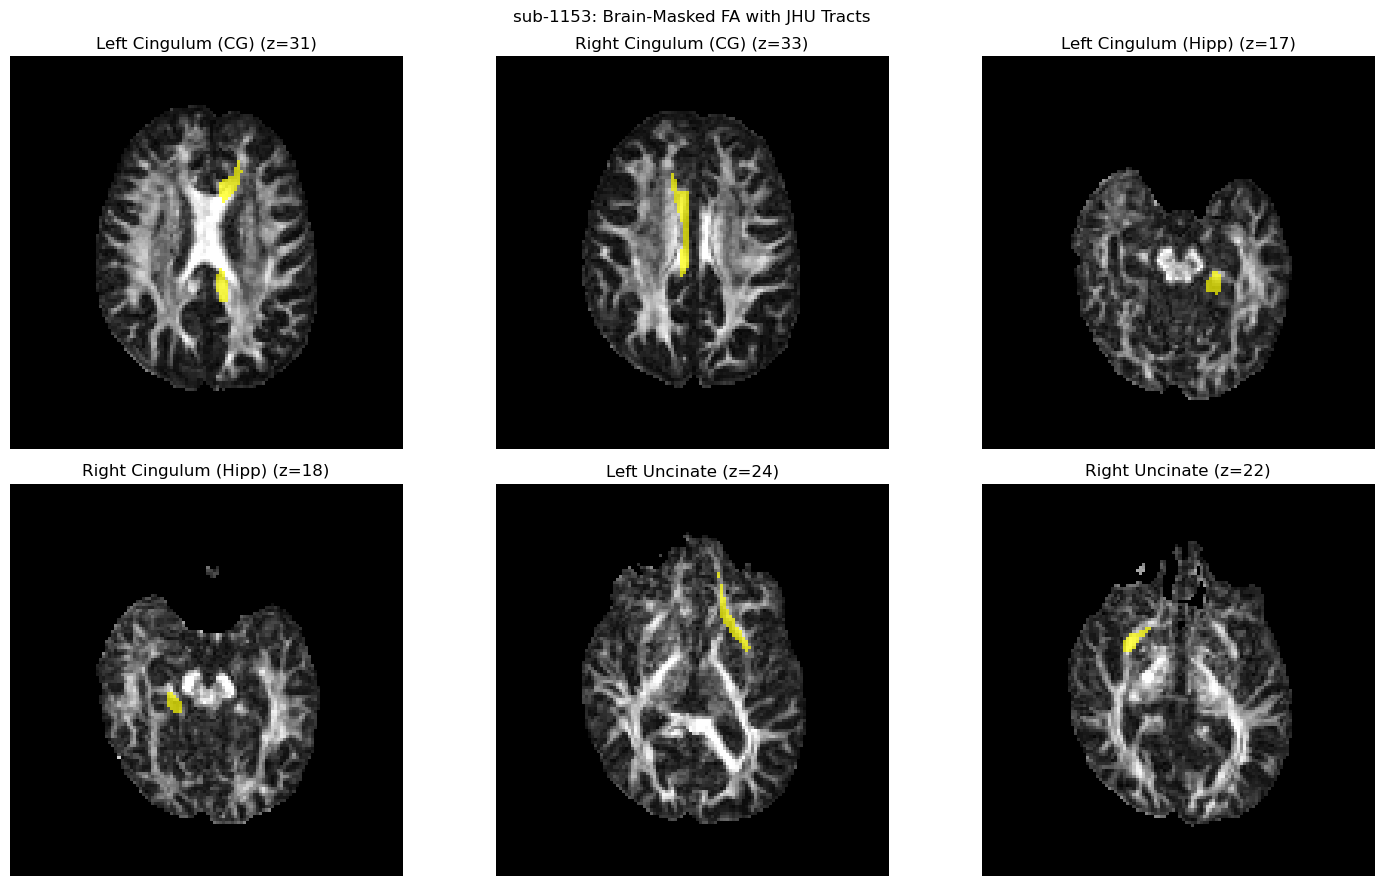

In [16]:

import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

base = Path.home() / "NSCI270"
subject = "sub-1153"

# Load FA image
fa_img = nib.load(str(base / "dti_preprocessed" / subject / "FA.nii.gz"))
fa = fa_img.get_fdata()

# Load brain mask
brain_img = nib.load(str(base / "dti_preprocessed" / subject / "brain_mask.nii.gz"))
brain_mask = brain_img.get_fdata() > 0

# Remove background noise
fa_clean = np.where(brain_mask, fa, 0)

# Six white matter tracts
tracts = [4, 5, 6, 7, 16, 17]

names = [
    "Left Cingulum (CG)",
    "Right Cingulum (CG)",
    "Left Cingulum (Hipp)",
    "Right Cingulum (Hipp)",
    "Left Uncinate",
    "Right Uncinate"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, tract, name in zip(axes.flat, tracts, names):

    path = base / "tract_analysis" / subject / f"tract_{tract}_brain.nii.gz"
    mask_img = nib.load(str(path))
    mask = mask_img.get_fdata() > 0

    if mask.shape != fa.shape or not np.allclose(
        mask_img.affine, fa_img.affine, atol=1e-3
    ):
        raise ValueError(f"Tract {tract} is not on the FA image grid")

    # Select slice containing tract
    coords = np.where(mask)
    slice_z = int(np.median(coords[2]))

    # Display FA image
    ax.imshow(
        fa_clean[:, :, slice_z].T,
        cmap="gray",
        origin="lower",
        vmin=0,
        vmax=0.8
    )

    # Display tract overlay
    overlay = np.ma.masked_where(
        ~mask[:, :, slice_z],
        mask[:, :, slice_z]
    )

    ax.imshow(
        overlay.T,
        cmap="autumn",
        origin="lower",
        alpha=0.7,
        vmin=0,
        vmax=1
    )

    ax.set_title(f"{name} (z={slice_z})")
    ax.axis("off")

plt.suptitle("sub-1153: Brain-Masked FA with JHU Tracts")
plt.tight_layout()
plt.show()


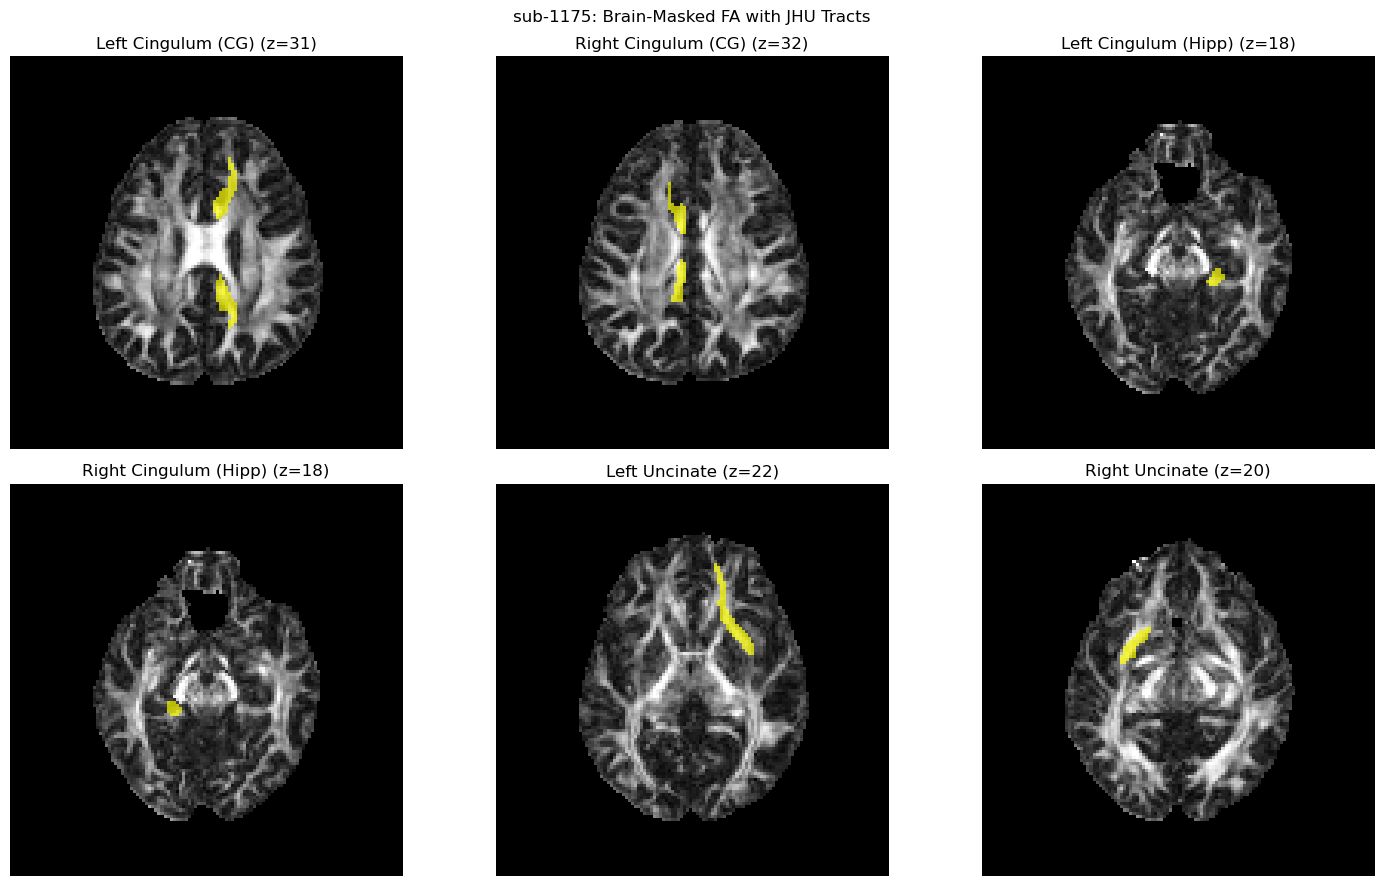

In [17]:

import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

base = Path.home() / "NSCI270"
subject = "sub-1175"

# Load FA image
fa_img = nib.load(str(base / "dti_preprocessed" / subject / "FA.nii.gz"))
fa = fa_img.get_fdata()

# Load brain mask
brain_img = nib.load(str(base / "dti_preprocessed" / subject / "brain_mask.nii.gz"))
brain_mask = brain_img.get_fdata() > 0

# Remove background noise
fa_clean = np.where(brain_mask, fa, 0)

# Six white matter tracts
tracts = [4, 5, 6, 7, 16, 17]

names = [
    "Left Cingulum (CG)",
    "Right Cingulum (CG)",
    "Left Cingulum (Hipp)",
    "Right Cingulum (Hipp)",
    "Left Uncinate",
    "Right Uncinate"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, tract, name in zip(axes.flat, tracts, names):

    path = base / "tract_analysis" / subject / f"tract_{tract}_brain.nii.gz"
    mask_img = nib.load(str(path))
    mask = mask_img.get_fdata() > 0

    if mask.shape != fa.shape or not np.allclose(
        mask_img.affine, fa_img.affine, atol=1e-3
    ):
        raise ValueError(f"Tract {tract} is not on the FA image grid")

    # Select slice containing tract
    coords = np.where(mask)
    slice_z = int(np.median(coords[2]))

    # Display brain-masked FA image
    ax.imshow(
        fa_clean[:, :, slice_z].T,
        cmap="gray",
        origin="lower",
        vmin=0,
        vmax=0.8
    )

    # Display tract overlay
    overlay = np.ma.masked_where(
        ~mask[:, :, slice_z],
        mask[:, :, slice_z]
    )

    ax.imshow(
        overlay.T,
        cmap="autumn",
        origin="lower",
        alpha=0.7,
        vmin=0,
        vmax=1
    )

    ax.set_title(f"{name} (z={slice_z})")
    ax.axis("off")

plt.suptitle("sub-1175: Brain-Masked FA with JHU Tracts")
plt.tight_layout()
plt.show()


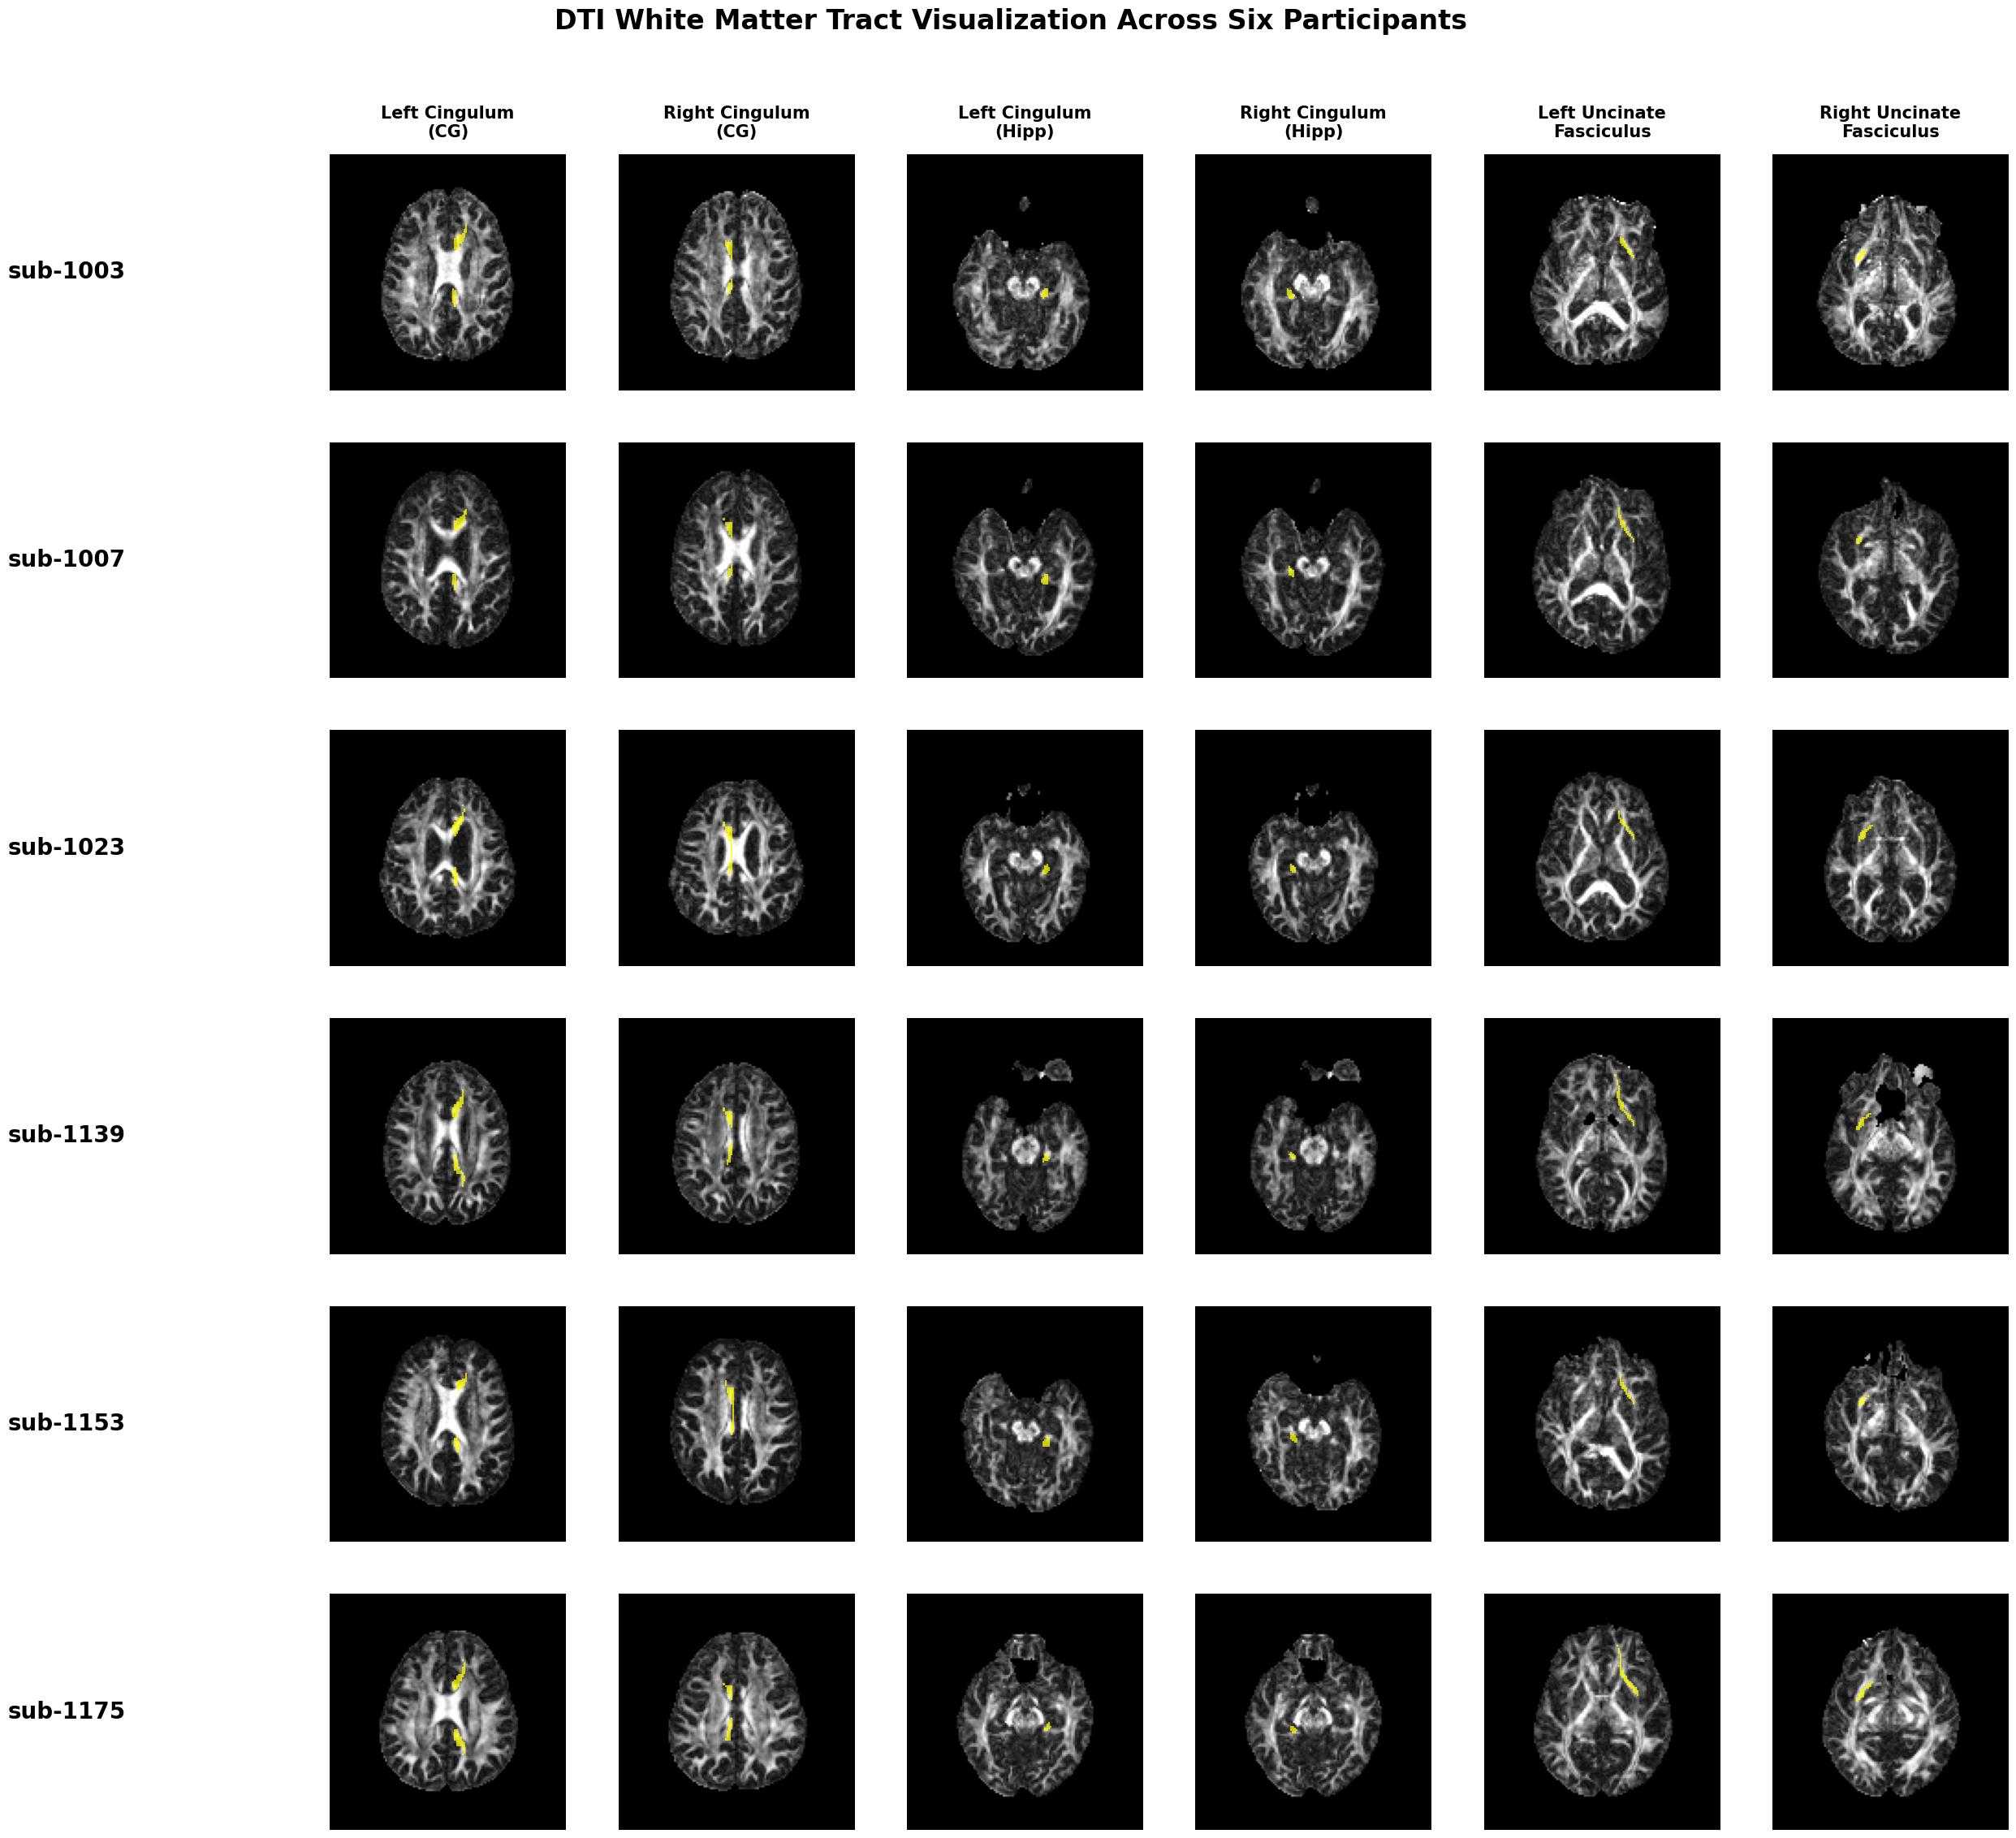

Successfully saved labeled figure!
File location: /nas/longleaf/home/emtubbs/NSCI270/tract_analysis/all_subjects_tracts_labeled.png


In [20]:

import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ==========================================
# 1. Set up subjects and tracts
# ==========================================

base = Path.home() / "NSCI270"

subjects = [
    "sub-1003",
    "sub-1007",
    "sub-1023",
    "sub-1139",
    "sub-1153",
    "sub-1175"
]

tracts = [4, 5, 6, 7, 16, 17]

tract_names = [
    "Left Cingulum\n(CG)",
    "Right Cingulum\n(CG)",
    "Left Cingulum\n(Hipp)",
    "Right Cingulum\n(Hipp)",
    "Left Uncinate\nFasciculus",
    "Right Uncinate\nFasciculus"
]

# ==========================================
# 2. Create the 6 x 6 figure
# ==========================================

fig, axes = plt.subplots(
    6, 6,
    figsize=(26, 24),
    facecolor="white"
)

# ==========================================
# 3. Load and display each subject
# ==========================================

for row, subject in enumerate(subjects):

    dti_dir = base / "dti_preprocessed" / subject

    # Load FA image
    fa_img = nib.load(str(dti_dir / "FA.nii.gz"))
    fa = fa_img.get_fdata()

    # Load brain mask
    brain_img = nib.load(
        str(dti_dir / "brain_mask.nii.gz")
    )

    brain_mask = brain_img.get_fdata() > 0

    # Remove background noise
    fa_clean = np.where(brain_mask, fa, 0)

    for col, tract in enumerate(tracts):

        ax = axes[row, col]

        # sub-1003 has a different folder structure
        if subject == "sub-1003":
            mask_path = (
                base / "tract_analysis" / subject
                / "tract_masks"
                / f"tract_{tract}_brain.nii.gz"
            )
        else:
            mask_path = (
                base / "tract_analysis" / subject
                / f"tract_{tract}_brain.nii.gz"
            )

        # Load tract mask
        mask_img = nib.load(str(mask_path))
        mask = mask_img.get_fdata() > 0

        # Verify image dimensions and alignment
        if mask.shape != fa.shape or not np.allclose(
            mask_img.affine,
            fa_img.affine,
            atol=1e-3
        ):
            raise ValueError(
                f"Image mismatch: {subject}, tract {tract}"
            )

        # Find representative slice
        coords = np.where(mask)

        if len(coords[0]) == 0:
            raise ValueError(
                f"Empty tract: {subject}, tract {tract}"
            )

        z = int(np.median(coords[2]))

        # Display FA background
        ax.imshow(
            fa_clean[:, :, z].T,
            cmap="gray",
            origin="lower",
            vmin=0,
            vmax=0.8
        )

        # Display colored tract overlay
        overlay = np.ma.masked_where(
            ~mask[:, :, z],
            mask[:, :, z]
        )

        ax.imshow(
            overlay.T,
            cmap="autumn",
            origin="lower",
            alpha=0.75,
            vmin=0,
            vmax=1
        )

        # Hide axes
        ax.set_axis_off()

        # Add tract titles across top row
        if row == 0:
            ax.set_title(
                tract_names[col],
                fontsize=15,
                fontweight="bold",
                pad=15
            )

# ==========================================
# 4. Adjust spacing
# ==========================================

fig.subplots_adjust(
    left=0.17,
    right=0.98,
    top=0.90,
    bottom=0.04,
    wspace=0.08,
    hspace=0.22
)

# ==========================================
# 5. Add LARGE subject names on the left
# ==========================================

for row, subject in enumerate(subjects):

    # Find the vertical center of each row
    position = axes[row, 0].get_position()

    center_y = (position.y0 + position.y1) / 2

    # Add subject name directly to the figure
    fig.text(
        0.025,
        center_y,
        subject,
        fontsize=20,
        fontweight="bold",
        color="black",
        ha="left",
        va="center"
    )

# ==========================================
# 6. Add main figure title
# ==========================================

fig.suptitle(
    "DTI White Matter Tract Visualization Across Six Participants",
    fontsize=24,
    fontweight="bold",
    y=0.975
)

# ==========================================
# 7. Save high-resolution PNG
# ==========================================

output = (
    base / "tract_analysis"
    / "all_subjects_tracts_labeled.png"
)

fig.savefig(
    output,
    dpi=200,
    bbox_inches="tight",
    facecolor="white"
)

# Display the figure
plt.show()

print("Successfully saved labeled figure!")
print("File location:", output)

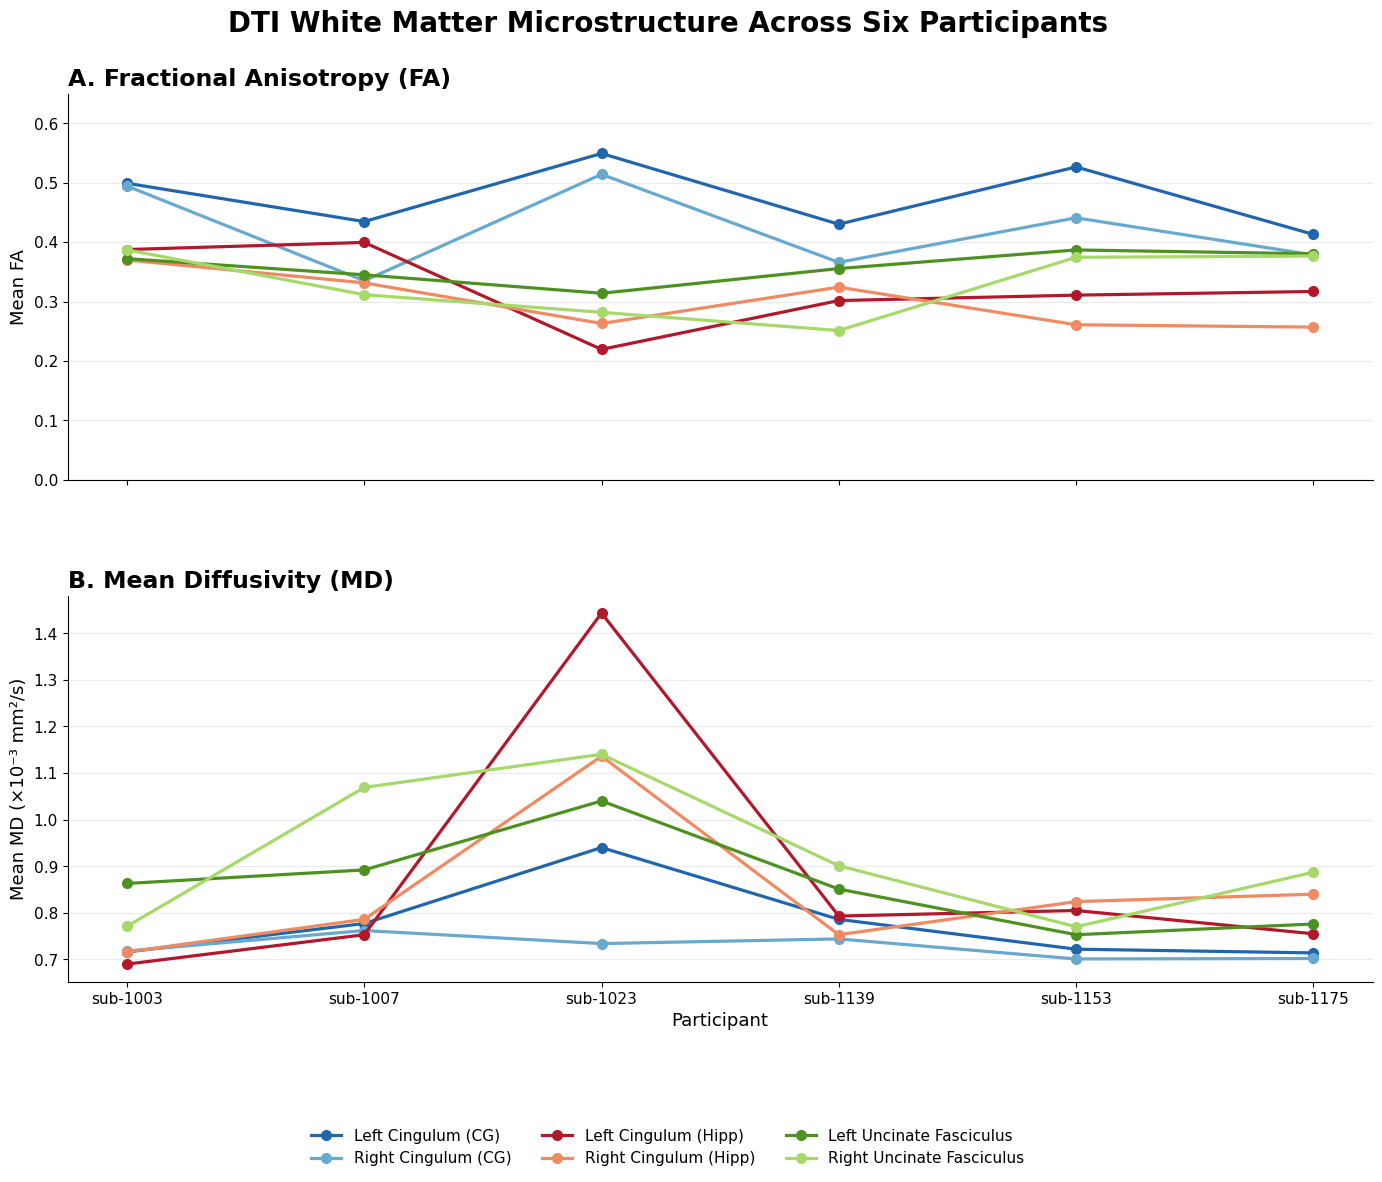

Figure successfully saved!
Location: /nas/longleaf/home/emtubbs/NSCI270/tract_analysis/FA_MD_comparison_all_subjects.png


In [21]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ==========================================
# 1. Load your DTI CSV
# ==========================================

base = Path.home() / "NSCI270"

csv_path = (
    base / "tract_analysis" /
    "all_subjects_FA_MD.csv"
)

df = pd.read_csv(csv_path)

# Clean up column names and numeric values
df.columns = df.columns.str.strip()

for col in ["tract", "voxel_count", "mean_FA", "mean_MD"]:
    df[col] = pd.to_numeric(df[col], errors="raise")

# ==========================================
# 2. Define subjects and tract names
# ==========================================

subjects = [
    "sub-1003",
    "sub-1007",
    "sub-1023",
    "sub-1139",
    "sub-1153",
    "sub-1175"
]

tract_names = {
    4: "Left Cingulum (CG)",
    5: "Right Cingulum (CG)",
    6: "Left Cingulum (Hipp)",
    7: "Right Cingulum (Hipp)",
    16: "Left Uncinate Fasciculus",
    17: "Right Uncinate Fasciculus"
}

colors = {
    4: "#2166AC",
    5: "#67A9CF",
    6: "#B2182B",
    7: "#EF8A62",
    16: "#4D9221",
    17: "#A6D96A"
}

# ==========================================
# 3. Validate the dataset
# ==========================================

assert len(df) == 36, "Expected 36 measurements"

assert not df[
    ["subject", "tract", "mean_FA", "mean_MD"]
].isna().any().any(), "Missing values found"

assert set(df["subject"]) == set(subjects)

assert set(df["tract"]) == set(tract_names)

assert not df.duplicated(
    ["subject", "tract"]
).any(), "Duplicate subject/tract rows"

# ==========================================
# 4. Create two-panel figure
# ==========================================

fig, axes = plt.subplots(
    2, 1,
    figsize=(15, 12),
    sharex=True
)

x = np.arange(len(subjects))

# Panel A: FA
ax = axes[0]

for tract, name in tract_names.items():

    data = (
        df[df["tract"] == tract]
        .set_index("subject")
        .reindex(subjects)
    )

    ax.plot(
        x,
        data["mean_FA"],
        marker="o",
        markersize=7,
        linewidth=2.3,
        color=colors[tract],
        label=name
    )

ax.set_title(
    "A. Fractional Anisotropy (FA)",
    fontsize=17,
    fontweight="bold",
    loc="left"
)

ax.set_ylabel("Mean FA", fontsize=13)
ax.set_ylim(0, 0.65)
ax.grid(axis="y", alpha=0.25)

# Panel B: MD
ax = axes[1]

for tract, name in tract_names.items():

    data = (
        df[df["tract"] == tract]
        .set_index("subject")
        .reindex(subjects)
    )

    # Convert MD from mm²/s to 10^-3 mm²/s
    md_scaled = data["mean_MD"] * 1000

    ax.plot(
        x,
        md_scaled,
        marker="o",
        markersize=7,
        linewidth=2.3,
        color=colors[tract],
        label=name
    )

ax.set_title(
    "B. Mean Diffusivity (MD)",
    fontsize=17,
    fontweight="bold",
    loc="left"
)

ax.set_ylabel(
    "Mean MD (×10⁻³ mm²/s)",
    fontsize=13
)

ax.set_xlabel("Participant", fontsize=13)
ax.grid(axis="y", alpha=0.25)

# ==========================================
# 5. Format both graphs
# ==========================================

for ax in axes:
    ax.set_xticks(x)
    ax.set_xticklabels(subjects, fontsize=11)
    ax.tick_params(axis="y", labelsize=11)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# One legend for the entire figure
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.015),
    ncol=3,
    fontsize=11,
    frameon=False
)

fig.suptitle(
    "DTI White Matter Microstructure Across Six Participants",
    fontsize=20,
    fontweight="bold",
    y=0.99
)

fig.subplots_adjust(
    top=0.92,
    bottom=0.18,
    left=0.10,
    right=0.97,
    hspace=0.30
)

# ==========================================
# 6. Save high-resolution PNG
# ==========================================

output = (
    base / "tract_analysis" /
    "FA_MD_comparison_all_subjects.png"
)

fig.savefig(
    output,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Figure successfully saved!")
print("Location:", output)


Combined PET-DTI dataset:


,subject,mean_FA,mean_MD,amyloid_SUVR,tau_SUVR
0,sub-1023,0.356945,0.001072,1.141,1.145
1,sub-1139,0.338111,0.000805,1.022,1.080
2,sub-1153,0.383418,0.000762,0.992,1.118
3,sub-1175,0.353719,0.000779,0.992,1.069


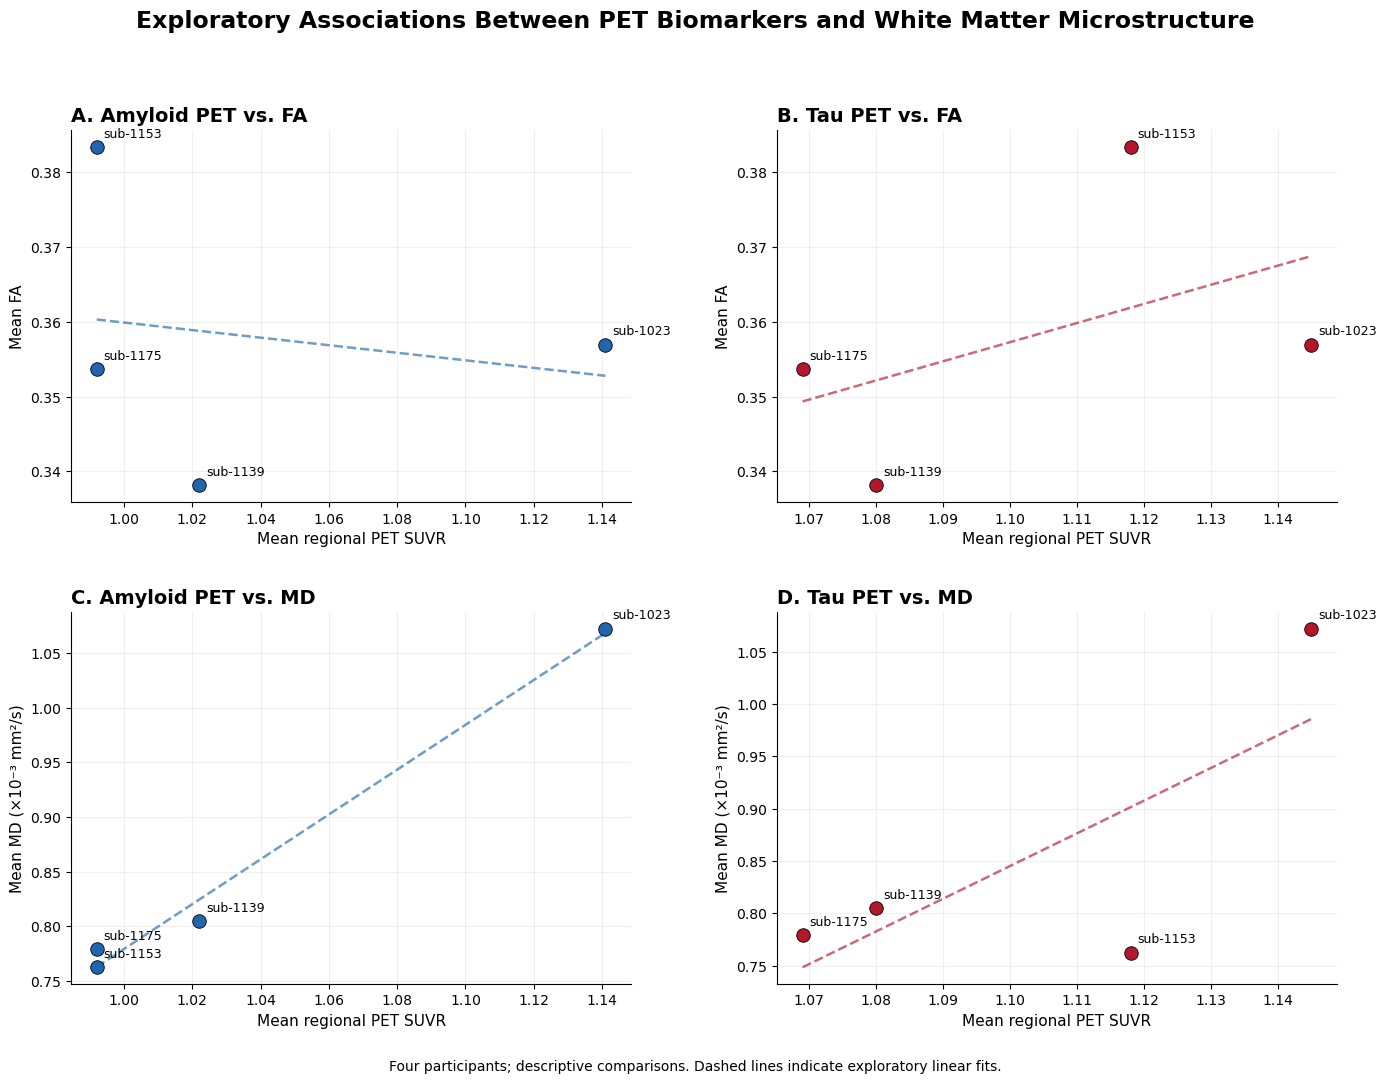

Figure saved to:
/nas/longleaf/home/emtubbs/NSCI270/tract_analysis/PET_DTI_Final_Figure.png


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ==========================================
# 1. Load PET and DTI measurements
# ==========================================

base = Path.home() / "NSCI270" / "tract_analysis"

dti = pd.read_csv(base / "all_subjects_FA_MD.csv")
pet = pd.read_csv(base / "pet_suvr_summary_4subjects.csv")

dti.columns = dti.columns.str.strip()
pet.columns = pet.columns.str.strip()

dti["subject"] = dti["subject"].str.strip()
pet["subject"] = pet["subject"].str.strip()
pet["tracer"] = pet["tracer"].str.strip().str.lower()

# ==========================================
# 2. Average DTI measurements per participant
# ==========================================

# All six selected white matter regions
tracts = [4, 5, 6, 7, 16, 17]

dti = dti[dti["tract"].isin(tracts)].copy()

dti_summary = (
    dti.groupby("subject", as_index=False)
       .agg(
           mean_FA=("mean_FA", "mean"),
           mean_MD=("mean_MD", "mean")
       )
)

# ==========================================
# 3. Organize PET SUVR measurements
# ==========================================

# WANDA's mean across 89 aparc regions
pet["aparc_region_suvr_mean"] = pd.to_numeric(
    pet["aparc_region_suvr_mean"],
    errors="raise"
)

pet_summary = pet.pivot(
    index="subject",
    columns="tracer",
    values="aparc_region_suvr_mean"
).reset_index()

pet_summary = pet_summary.rename(
    columns={
        "amyloid": "amyloid_SUVR",
        "tau": "tau_SUVR"
    }
)

# ==========================================
# 4. Combine PET and DTI datasets
# ==========================================

combined = pd.merge(
    dti_summary,
    pet_summary,
    on="subject",
    how="inner"
)

combined = combined.sort_values("subject")

required = [
    "mean_FA", "mean_MD",
    "amyloid_SUVR", "tau_SUVR"
]

if combined[required].isna().any().any():
    raise ValueError("Missing measurements found")

if len(combined) != 4:
    raise ValueError(
        f"Expected 4 participants, found {len(combined)}"
    )

# Display combined measurements
print("Combined PET-DTI dataset:")
display(combined.round(6))

# ==========================================
# 5. Create the four-panel figure
# ==========================================

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 11)
)

panels = [
    ("amyloid_SUVR", "mean_FA",
     "A. Amyloid PET vs. FA", "#2166AC"),

    ("tau_SUVR", "mean_FA",
     "B. Tau PET vs. FA", "#B2182B"),

    ("amyloid_SUVR", "mean_MD",
     "C. Amyloid PET vs. MD", "#2166AC"),

    ("tau_SUVR", "mean_MD",
     "D. Tau PET vs. MD", "#B2182B")
]

for ax, (xcol, ycol, title, color) in zip(
    axes.flat, panels
):

    x = combined[xcol].to_numpy(dtype=float)

    # Scale MD for easier interpretation
    if ycol == "mean_MD":
        y = combined[ycol].to_numpy(dtype=float) * 1000
        ylabel = "Mean MD (×10⁻³ mm²/s)"
    else:
        y = combined[ycol].to_numpy(dtype=float)
        ylabel = "Mean FA"

    # Participant data points
    ax.scatter(
        x, y,
        s=95,
        color=color,
        edgecolor="black",
        linewidth=0.6,
        zorder=3
    )

    # Label each participant
    for xi, yi, subject in zip(
        x, y, combined["subject"]
    ):
        ax.annotate(
            subject,
            (xi, yi),
            xytext=(5, 7),
            textcoords="offset points",
            fontsize=9
        )

    # Exploratory linear trend
    if len(np.unique(x)) > 1:
        slope, intercept = np.polyfit(x, y, 1)
        x_line = np.linspace(x.min(), x.max(), 100)

        ax.plot(
            x_line,
            slope * x_line + intercept,
            linestyle="--",
            color=color,
            alpha=0.65,
            linewidth=1.8
        )

    ax.set_title(
        title,
        fontsize=14,
        fontweight="bold",
        loc="left"
    )

    ax.set_xlabel(
        "Mean regional PET SUVR",
        fontsize=11
    )

    ax.set_ylabel(ylabel, fontsize=11)
    ax.grid(alpha=0.2)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# ==========================================
# 6. Add overall title
# ==========================================

fig.suptitle(
    "Exploratory Associations Between PET Biomarkers "
    "and White Matter Microstructure",
    fontsize=17,
    fontweight="bold",
    y=0.99
)

fig.text(
    0.5, 0.025,
    "Four participants; descriptive comparisons. "
    "Dashed lines indicate exploratory linear fits.",
    ha="center",
    fontsize=10
)

plt.tight_layout(
    rect=[0, 0.05, 1, 0.95],
    h_pad=3,
    w_pad=3
)

# ==========================================
# 7. Save the final figure
# ==========================================

output = base / "PET_DTI_Final_Figure.png"

fig.savefig(
    output,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Figure saved to:")
print(output)


In [2]:

import pandas as pd
import numpy as np
from pathlib import Path

base = Path.home() / "NSCI270" / "tract_analysis"

# Load datasets
dti = pd.read_csv(base / "all_subjects_FA_MD.csv")
pet = pd.read_csv(base / "pet_suvr_summary_4subjects.csv")

# Clean column names
dti.columns = dti.columns.str.strip()
pet.columns = pet.columns.str.strip()

# Mean DTI values across the six selected tracts
dti_summary = (
    dti.groupby("subject", as_index=False)
    .agg(
        mean_FA=("mean_FA", "mean"),
        mean_MD=("mean_MD", "mean")
    )
)

# Organize PET SUVR values
pet_summary = (
    pet.pivot(
        index="subject",
        columns="tracer",
        values="aparc_region_suvr_mean"
    )
    .reset_index()
    .rename(
        columns={
            "amyloid": "amyloid_SUVR",
            "tau": "tau_SUVR"
        }
    )
)

# Combine datasets
combined = pd.merge(
    dti_summary,
    pet_summary,
    on="subject",
    how="inner"
)

print("Participants available:", len(combined))
display(combined)


Participants available: 4


,subject,mean_FA,mean_MD,amyloid_SUVR,tau_SUVR
0,sub-1023,0.356945,0.001072,1.141,1.145
1,sub-1139,0.338111,0.000805,1.022,1.080
2,sub-1153,0.383418,0.000763,0.992,1.118
3,sub-1175,0.353719,0.000779,0.992,1.069


In [3]:

n = len(combined)

predictors = 3  # Amyloid, tau, and age
parameters = predictors + 1  # Include intercept

residual_df = n - parameters

print("Participants:", n)
print("Predictors:", predictors)
print("Residual degrees of freedom:", residual_df)

if residual_df <= 0:
    print(
        "Multiple regression with amyloid, tau, and age "
        "cannot be reliably estimated with this sample."
    )


Participants: 4
Predictors: 3
Residual degrees of freedom: 0
Multiple regression with amyloid, tau, and age cannot be reliably estimated with this sample.
